# Series temporales en situación de criticidad

**Trabajo de Fin de Máster — Máster Universitario en Inteligencia Artificial (VIU)**

Autor: Julián Campos Navarro

Este cuaderno reúne el código utilizado en la memoria del TFM: la carga y limpieza
de los datos, todas las figuras y todas las tablas. Está organizado en el mismo orden que la memoria:

1. Configuración y carga de los datos
2. Figuras de la introducción y la metodología
3. Figuras del marco teórico
4. Ejemplos de cálculo de la metodología
5. Resultados: indicadores sobre las series originales
6. Resultados: indicadores sobre los residuos
7. Resultados: ralentización crítica y tiempo de recuperación
8. Resultados: *flickering*

Todas las figuras se guardan en la carpeta `FIGURAS` definida en la primera sección. Los ficheros de las series de cotización se pueden encontrar en mi repositorio de GitHub del TFM (https://github.com/MrJuli107/TFM).

## 1. Configuración y carga de los datos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import warnings
import matplotlib.dates as mdates
from matplotlib.patches import Ellipse
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm, skewnorm
from sklearn.mixture import GaussianMixture

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

RUTA_DATOS = '/content/drive/MyDrive/TFM/DataFinanciera/'
FIGURAS    = '/content/drive/MyDrive/TFM/Figuras/'
os.makedirs(FIGURAS, exist_ok=True)

# Colores de cada activo (los mismos en todas las figuras)
AZUL, ROJO, VERDE = '#1f3b73', '#b03a2e', '#2e7d4f'

# Fechas clave
LEHMAN     = pd.Timestamp('2008-09-15')
ULTIMO_DIA = '2008-09-12'                      # última sesión antes de la quiebra
CALMA      = slice('2005-01-01', '2007-06-30')  # periodo de referencia
PRE        = slice('2007-07-01', ULTIMO_DIA)    # periodo previo a la quiebra

def banda_2008(ax):
    """Banda gris que marca el año 2008."""
    ax.axvspan(pd.Timestamp('2008-01-01'), pd.Timestamp('2008-12-31'),
               color='gray', alpha=0.15, zorder=0, lw=0)

def formato(ax, paso_anios=2):
    """Formato común: cuadrícula discontinua, sin bordes superior y derecho."""
    ax.grid(True, linestyle='--', alpha=0.45)
    for lado in ('top', 'right'):
        ax.spines[lado].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator(paso_anios))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

def guardar(fig, nombre, dpi=200):
    fig.savefig(FIGURAS + nombre, dpi=dpi, facecolor='white')
    plt.show()

### 1.1 Funciones de carga

Los ficheros de **Investing.com** incluyen una *byte order mark* al comienzo (de ahí `utf-8-sig`),
usan el formato de fecha `dd.mm.aaaa`, el punto como separador de miles y la coma como separador
decimal, y vienen ordenados de más reciente a más antiguo.

Los ficheros de la **FRED** usan el formato `aaaa-mm-dd` y el punto decimal, pero incluyen los
festivos entre semana como valores vacíos, que eliminamos (no los rellenamos para no crear
valores que nunca existieron ni aumentar artificialmente la autocorrelación).

In [ ]:
def cargar_investing(ruta, columna='Último'):
    """Lee un CSV de Investing.com y devuelve una Serie de precios
    (por defecto, de cierre) indexada por fecha, ordenada cronológicamente."""
    df = pd.read_csv(ruta, encoding='utf-8-sig')
    df.columns = [c.strip() for c in df.columns]

    fechas = pd.to_datetime(df['Fecha'], format='%d.%m.%Y')

    precios = (df[columna].astype(str)
                          .str.replace('.', '', regex=False)
                          .str.replace(',', '.', regex=False)
                          .astype(float))

    s = pd.Series(precios.values, index=fechas, name='precio')
    return s.sort_index().dropna()


def cargar_fred(ruta, columna):
    """Lee un CSV de la FRED y devuelve una Serie indexada por fecha.
    Los días sin dato (festivos entre semana) se eliminan."""
    df = pd.read_csv(ruta)
    fechas  = pd.to_datetime(df['observation_date'])
    valores = pd.to_numeric(df[columna], errors='coerce')
    s = pd.Series(valores.values, index=fechas, name='precio')
    return s.sort_index().dropna()

In [ ]:
citi = cargar_investing(RUTA_DATOS + 'Citigroup_alldata.csv')
print(citi.head(3))
print(citi.tail(3))
print('observaciones:', len(citi))
print('rango:', citi.index.min().date(), '->', citi.index.max().date())

Fecha
2000-07-03    468.28
2000-07-05    474.38
2000-07-06    479.06
Name: precio, dtype: float64
Fecha
2016-10-26    50.01
2016-10-27    49.93
2016-10-28    49.56
Name: precio, dtype: float64
observaciones: 4108
rango: 2000-07-03 -> 2016-10-28


In [ ]:
irs  = cargar_fred(RUTA_DATOS + 'IRS2Y_alldata.csv', 'DSWP2')
sp   = cargar_investing(RUTA_DATOS + 'SP500_alldata.csv')
msft = cargar_investing(RUTA_DATOS + 'MSFT_alldata.csv')

for nombre, s in [('Citigroup', citi), ('IRS 2Y', irs), ('S&P 500', sp), ('Microsoft', msft)]:
    print(f'{nombre:10s} {len(s):5d} obs.  {s.index.min().date()} -> {s.index.max().date()}  '
          f'valores ausentes: {s.isna().sum()}')

# Huecos de la FRED eliminados
bruto = pd.read_csv(RUTA_DATOS + 'IRS2Y_alldata.csv')
print('\nFilas de la FRED sin dato (eliminadas):', pd.to_numeric(bruto['DSWP2'], errors='coerce').isna().sum())

Citigroup   4108 obs.  2000-07-03 -> 2016-10-28  valores ausentes: 0
IRS 2Y      4081 obs.  2000-07-03 -> 2016-10-28  valores ausentes: 0
S&P 500     4108 obs.  2000-07-03 -> 2016-10-28  valores ausentes: 0
Microsoft   4109 obs.  2000-07-03 -> 2016-10-28  valores ausentes: 0

Filas de la FRED sin dato (eliminadas): 179


### 1.2 Ejemplo de limpieza (tabla de la metodología)

In [ ]:
crudo = pd.read_csv(RUTA_DATOS + 'SP500_alldata.csv', encoding='utf-8-sig')
crudo.columns = [c.strip() for c in crudo.columns]
fila = crudo[crudo['Fecha'] == '15.09.2008'].iloc[0]
print('Valor original :', repr(fila['Último']), '(texto)')
print('Valor limpio   :', sp.loc['2008-09-15'], '(número)')

Valor original : '1.192,70' (texto)
Valor limpio   : 1192.7 (número)


## 2. Figuras de la introducción y la metodología

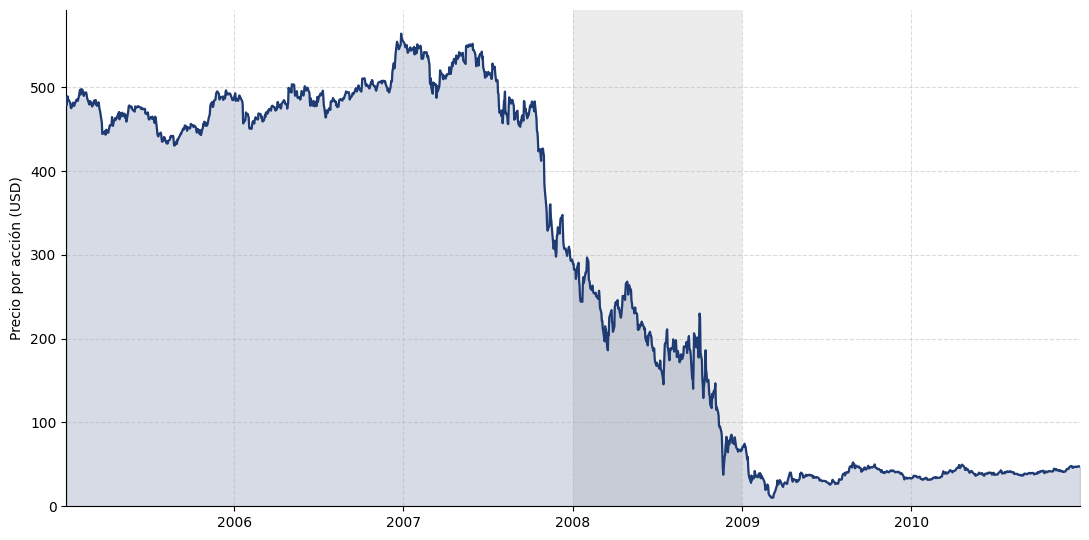

In [ ]:
# Figura 1.1: Citigroup entre 2005 y 2010
s = citi['2005-01-01':'2010-12-31']
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axvspan(pd.Timestamp('2008-01-01'), pd.Timestamp('2008-12-31'), color='gray', alpha=0.15, zorder=0, lw=0)
ax.fill_between(s.index, s.values, 0, color=AZUL, alpha=0.18, zorder=1)
ax.plot(s.index, s.values, color=AZUL, lw=1.6, zorder=3)
ax.set_ylabel('Precio por acción (USD)')
ax.set_xlim(s.index[0], s.index[-1]); ax.set_ylim(0, s.max() * 1.05)
formato(ax, 1)
fig.tight_layout(); guardar(fig, 'citigroup_2005_2010.png')

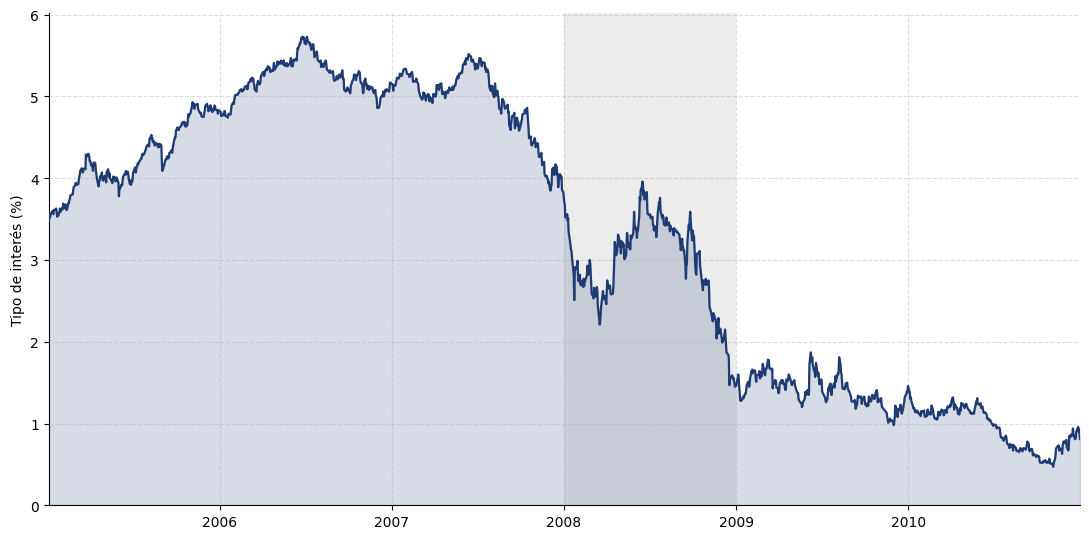

In [ ]:
# Figura 5.1: IRS 2Y entre 2005 y 2010
s = irs['2005-01-01':'2010-12-31']
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axvspan(pd.Timestamp('2008-01-01'), pd.Timestamp('2008-12-31'), color='gray', alpha=0.15, zorder=0, lw=0)
ax.fill_between(s.index, s.values, 0, color=AZUL, alpha=0.18, zorder=1)
ax.plot(s.index, s.values, color=AZUL, lw=1.6, zorder=3)
ax.set_ylabel('Tipo de interés (%)')
ax.set_xlim(s.index[0], s.index[-1]); ax.set_ylim(0, s.max() * 1.05)
formato(ax, 1)
fig.tight_layout(); guardar(fig, 'irs2y_2005_2010.png')

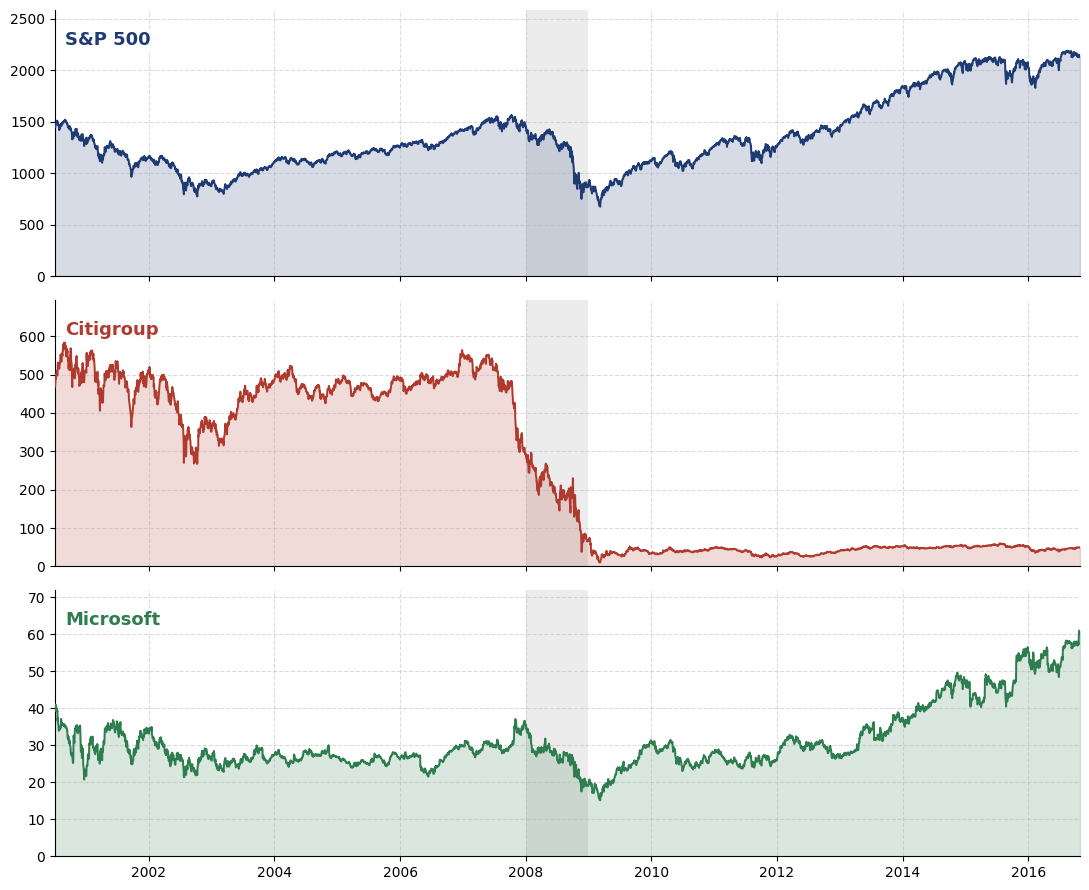

In [ ]:
# Figura 5.2: las tres series de renta variable (2000-2016)
acciones = [('S&P 500', sp, AZUL), ('Citigroup', citi, ROJO), ('Microsoft', msft, VERDE)]

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, (nombre, s, color) in zip(axes, acciones):
    banda_2008(ax)
    ax.fill_between(s.index, s.values, 0, color=color, alpha=0.18, zorder=1)
    ax.plot(s.index, s.values, color=color, lw=1.4, zorder=3)
    ax.set_ylim(0, s.max() * 1.18)
    ax.text(0.01, 0.92, nombre, transform=ax.transAxes, fontsize=13, fontweight='bold',
            color=color, va='top', zorder=5,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2))
    formato(ax)
axes[-1].set_xlim(sp.index[0], sp.index[-1])
fig.tight_layout(); guardar(fig, 'tres_series_2000_2016_ejes.png')

## 3. Figuras del marco teórico

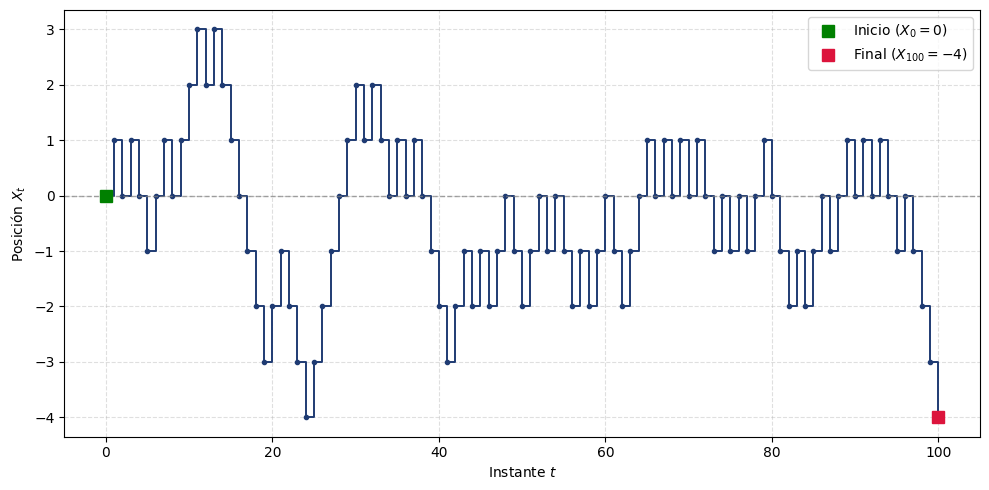

Posición final: -4


In [ ]:
# Figura: realización de un paseo aleatorio simple (100 pasos, semilla 67)
rng = np.random.default_rng(67)
pasos = rng.choice([-1, 1], size=100)
posicion = np.concatenate([[0], np.cumsum(pasos)])
t = np.arange(101)

fig, ax = plt.subplots(figsize=(10, 5))
ax.step(t, posicion, where='post', color=AZUL, lw=1.4)
ax.plot(t, posicion, 'o', color=AZUL, markersize=3)
ax.axhline(0, color='grey', lw=1, ls='--', alpha=0.7)
ax.plot(0, 0, 's', color='green', markersize=9, label='Inicio ($X_0 = 0$)', zorder=5)
ax.plot(100, posicion[-1], 's', color='crimson', markersize=9,
        label=f'Final ($X_{{100}} = {posicion[-1]}$)', zorder=5)
ax.set_xlabel('Instante $t$'); ax.set_ylabel('Posición $X_t$')
ax.grid(True, ls='--', alpha=0.4); ax.legend()
fig.tight_layout(); guardar(fig, 'paseo_aleatorio.png', dpi=150)
print('Posición final:', posicion[-1])

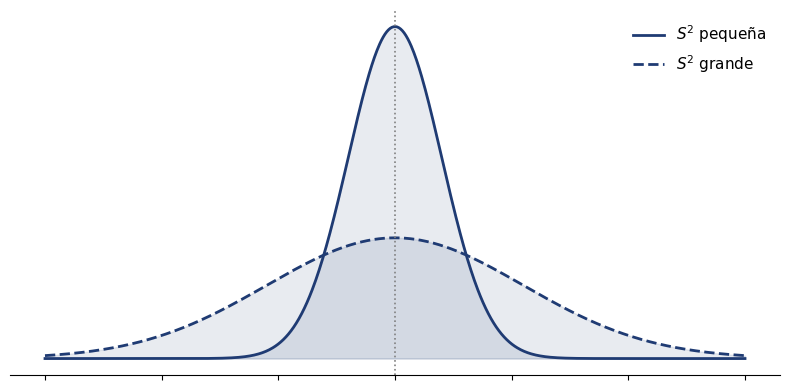

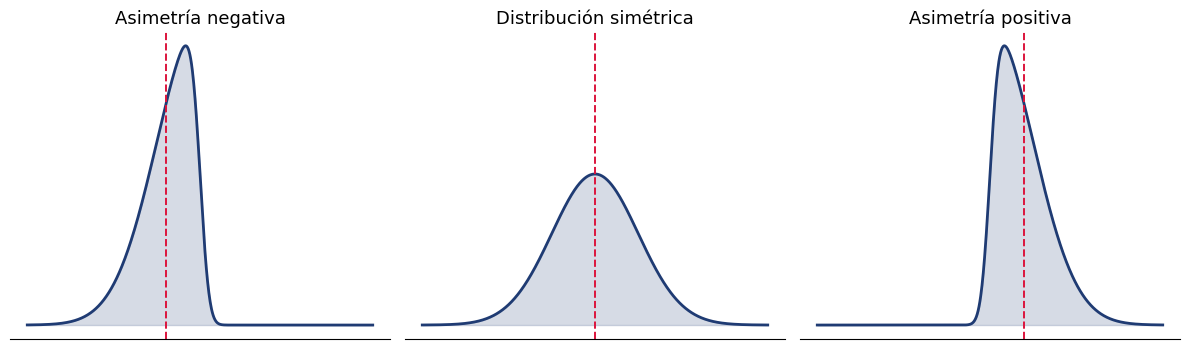

In [ ]:
# Figuras de la varianza y del sesgo
x = np.linspace(-6, 6, 800)
fig, ax = plt.subplots(figsize=(8, 4))
for sd, estilo, etiq in [(0.8, '-', r'$S^2$ pequeña'), (2.2, '--', r'$S^2$ grande')]:
    y = norm.pdf(x, 0, sd)
    ax.plot(x, y, color=AZUL, lw=2, ls=estilo, label=etiq)
    ax.fill_between(x, y, color=AZUL, alpha=0.10)
ax.axvline(0, color='grey', lw=1.2, ls=':')
ax.set_yticks([]); ax.set_xticklabels([]); ax.legend(frameon=False, fontsize=11)
for lado in ('top', 'right', 'left'): ax.spines[lado].set_visible(False)
fig.tight_layout(); guardar(fig, 'momentos_varianza.png')

x = np.linspace(-4, 4, 800)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (a, titulo) in zip(axes, [(-6, 'Asimetría negativa'), (0, 'Distribución simétrica'), (6, 'Asimetría positiva')]):
    y = skewnorm.pdf(x, a)
    ax.plot(x, y, color=AZUL, lw=2); ax.fill_between(x, y, color=AZUL, alpha=0.18)
    ax.axvline(skewnorm.mean(a), color='crimson', lw=1.4, ls='--')
    ax.set_title(titulo, fontsize=13); ax.set_yticks([]); ax.set_xticks([])
    for lado in ('top', 'right', 'left'): ax.spines[lado].set_visible(False)
fig.tight_layout(); guardar(fig, 'momentos_sesgo.png')

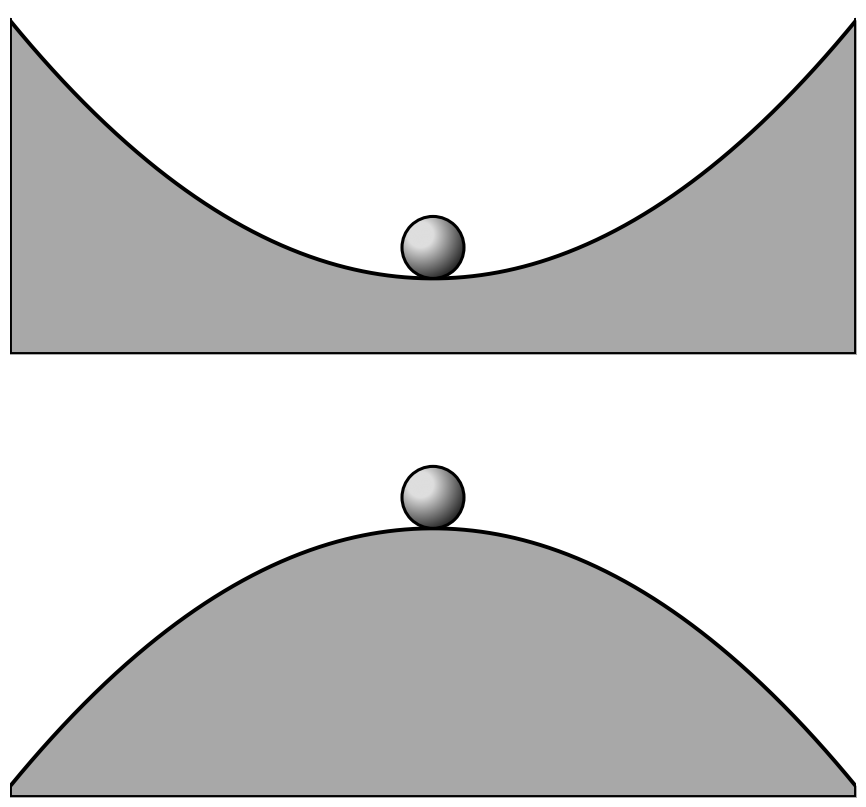

In [ ]:
# Figura: paisajes de estabilidad (equilibrio estable arriba, inestable abajo)
GRIS = '#a8a8a8'
FIGW, FIGH, L, R = 9.0, 8.2, 0.03, 0.97
XLIM, YLIM, RY, ALTO = (-1.06, 1.06), (-0.05, 1.45), 0.135, 0.42
RX = RY * ((ALTO * FIGH) / (YLIM[1] - YLIM[0])) / (((R - L) * FIGW) / (XLIM[1] - XLIM[0]))

def esfera(ax, cx, cy):
    yy, xx = np.mgrid[-1:1:500j, -1:1:500j]
    sombra = np.clip(1.30 - 0.72 * np.sqrt((xx + 0.40)**2 + (yy - 0.40)**2), 0, 1)
    sombra[xx**2 + yy**2 > 1] = np.nan
    im = ax.imshow(sombra, cmap='gray', vmin=0.02, vmax=1.15, extent=[cx-RX, cx+RX, cy-RY, cy+RY],
                   zorder=5, interpolation='bilinear', aspect='auto', origin='lower')
    ax.add_patch(Ellipse((cx, cy), 2*RX, 2*RY, facecolor='none', edgecolor='black', lw=2.2, zorder=6))
    im.set_clip_path(Ellipse((cx, cy), 2*RX, 2*RY, transform=ax.transData))

def panel(ax, y, y_bola):
    x = np.linspace(*XLIM, 800)
    ax.fill_between(x, y, YLIM[0], color=GRIS, zorder=1)
    ax.plot(x, y, color='black', lw=2.8, zorder=3)
    for xs, ys in [([x[0], x[0]], [YLIM[0], y[0]]), ([x[-1], x[-1]], [YLIM[0], y[-1]]), ([x[0], x[-1]], [YLIM[0], YLIM[0]])]:
        ax.plot(xs, ys, color='black', lw=2.8, zorder=3)
    esfera(ax, 0.0, y_bola + RY)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values(): sp_.set_visible(False)

x = np.linspace(*XLIM, 800)
fig = plt.figure(figsize=(FIGW, FIGH))
panel(fig.add_axes([L, 0.56, R - L, ALTO]), 0.28 + x**2, 0.28)   # valle: estable
panel(fig.add_axes([L, 0.02, R - L, ALTO]), 1.12 - x**2, 1.12)   # loma: inestable
guardar(fig, 'paisaje_valle_loma.png')

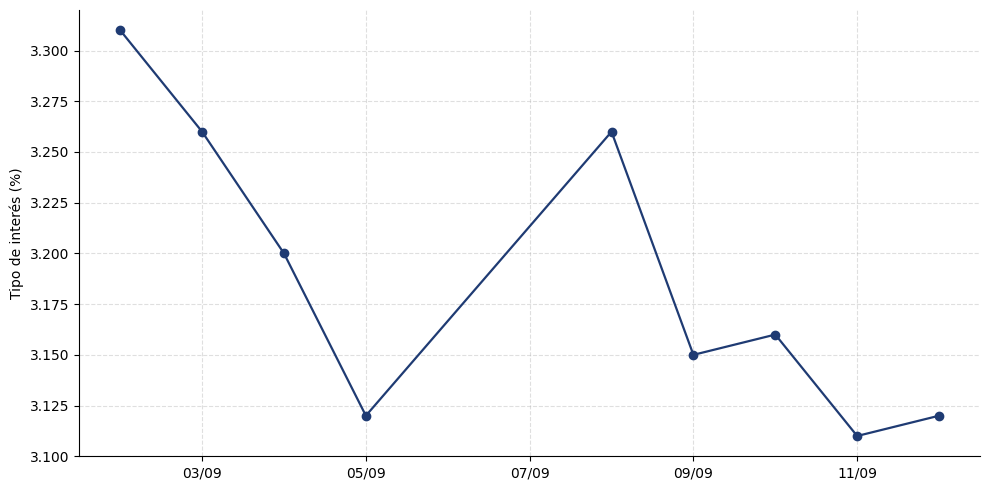

observation_date
2008-09-02    3.31
2008-09-03    3.26
2008-09-04    3.20
2008-09-05    3.12
2008-09-08    3.26
2008-09-09    3.15
2008-09-10    3.16
2008-09-11    3.11
2008-09-12    3.12
Name: precio, dtype: float64


In [ ]:
# Figura: IRS 2Y en los días previos a la quiebra de Lehman Brothers
s = irs['2008-09-02':'2008-09-12']
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(s.index, s.values, 'o-', color=AZUL, lw=1.6)
ax.set_ylabel('Tipo de interés (%)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
ax.grid(True, ls='--', alpha=0.4)
for lado in ('top', 'right'): ax.spines[lado].set_visible(False)
fig.tight_layout(); guardar(fig, 'irs2y_zoom_plot.png')
print(s)

## 4. Ejemplos de cálculo de la metodología

Ventanas deslizantes sobre el S&P 500 entre el 11 y el 19 de septiembre de 2008
(la semana de la quiebra y las dos sesiones anteriores), con ventanas muy pequeñas
para que el procedimiento pueda seguirse a mano.

In [ ]:
ejemplo = sp['2008-09-11':'2008-09-19']

tabla_var = pd.DataFrame({'Cierre': ejemplo,
                          'Varianza (m=3)': ejemplo.rolling(3).var()})
print(tabla_var.round(2))

tabla_lag = pd.DataFrame({'Cierre': ejemplo,
                          'Lag 1 (m=5)': ejemplo.rolling(5)
                                           .apply(lambda x: pd.Series(x).autocorr(1), raw=True)})
print(tabla_lag.round(3))

tabla_sesgo = pd.DataFrame({'Cierre': ejemplo, 'Sesgo (m=5)': ejemplo.rolling(5).skew()})
print(tabla_sesgo.round(3))

            Cierre  Varianza (m=3)
Fecha                             
2008-09-11  1249.0             NaN
2008-09-12  1251.7             NaN
2008-09-15  1192.7         1109.66
2008-09-16  1213.6          894.90
2008-09-17  1156.4          837.72
2008-09-18  1206.5          972.04
2008-09-19  1255.1         2435.61
            Cierre  Lag 1 (m=5)
Fecha                          
2008-09-11  1249.0          NaN
2008-09-12  1251.7          NaN
2008-09-15  1192.7          NaN
2008-09-16  1213.6          NaN
2008-09-17  1156.4        0.316
2008-09-18  1206.5       -0.408
2008-09-19  1255.1       -0.121
            Cierre  Sesgo (m=5)
Fecha                          
2008-09-11  1249.0          NaN
2008-09-12  1251.7          NaN
2008-09-15  1192.7          NaN
2008-09-16  1213.6          NaN
2008-09-17  1156.4       -0.513
2008-09-18  1206.5       -0.025
2008-09-19  1255.1        0.109


In [ ]:
# Contribución de cada observación al sesgo en la primera ventana completa (11-17 sep)
ventana = ejemplo.iloc[:5]
z = (ventana - ventana.mean()) / ventana.std()
m = len(ventana)
print(pd.DataFrame({'Cierre': ventana, 'z': z.round(3), 'z^3': (z**3).round(3)}))
print('Suma de z^3:', round((z**3).sum(), 3))
print('Sesgo G1   :', round(m / ((m - 1) * (m - 2)) * (z**3).sum(), 3), '| pandas:', round(ventana.skew(), 3))

            Cierre      z    z^3
Fecha                           
2008-09-11  1249.0  0.907  0.747
2008-09-12  1251.7  0.975  0.926
2008-09-15  1192.7 -0.499 -0.124
2008-09-16  1213.6  0.023  0.000
2008-09-17  1156.4 -1.406 -2.779
Suma de z^3: -1.23
Sesgo G1   : -0.513 | pandas: -0.513


## 5. Resultados: indicadores sobre las series originales

Funciones de los tres indicadores en ventana deslizante. La ventana es causal: el valor de cada
sesión solo depende de las `m` sesiones anteriores (incluida ella misma).

In [ ]:
def varianza_movil(s, m=60):
    return s.rolling(m).var()

def autocorr_movil(s, m=60, lag=1):
    return s.rolling(m).apply(lambda x: pd.Series(x).autocorr(lag=lag), raw=True)

def sesgo_movil(s, m=60):
    return s.rolling(m).skew()

INDICADORES = {'Varianza': varianza_movil, 'Lag 1': autocorr_movil, 'Sesgo': sesgo_movil}

### 5.1 Elección del precio (Tabla 6.1)

Para cada activo de renta variable e indicador, correlación de Pearson **mínima** entre las series
del indicador calculadas con los precios de cierre, apertura, máximo y mínimo.

In [ ]:
COLUMNAS = ['Último', 'Apertura', 'Máximo', 'Mínimo']
ficheros = {'S&P 500': 'SP500_alldata.csv', 'Citigroup': 'Citigroup_alldata.csv', 'Microsoft': 'MSFT_alldata.csv'}

tabla_precios = {}
for nombre, fichero in ficheros.items():
    precios = {c: cargar_investing(RUTA_DATOS + fichero, columna=c) for c in COLUMNAS}
    fila = {}
    for ind, funcion in INDICADORES.items():
        df_ind = pd.DataFrame({c: funcion(s) for c, s in precios.items()}).dropna()
        corr = df_ind.corr().values
        fila[ind] = corr[np.triu_indices(len(COLUMNAS), 1)].min()
    tabla_precios[nombre] = fila
print(pd.DataFrame(tabla_precios).T.round(3))

           Varianza  Lag 1  Sesgo
S&P 500       0.993  0.928  0.967
Citigroup     0.992  0.925  0.953
Microsoft     0.995  0.929  0.970


### 5.2 Varianza

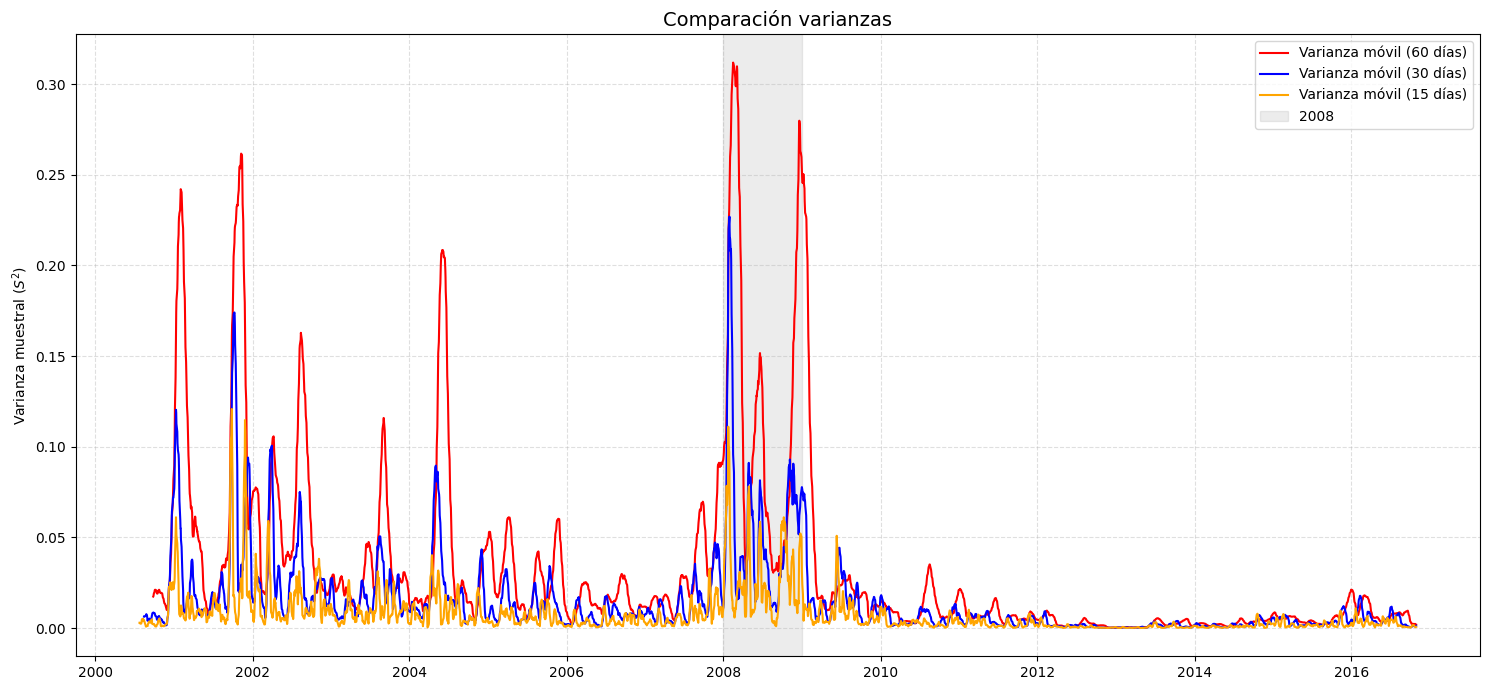

S&P 500    15-30: 0.69  15-60: 0.46  30-60: 0.67
Citigroup  15-30: 0.77  15-60: 0.56  30-60: 0.74
Microsoft  15-30: 0.68  15-60: 0.43  30-60: 0.69
IRS 2Y     15-30: 0.69  15-60: 0.49  30-60: 0.70


In [ ]:
# Figura 6.1: comparación de ventanas de 15, 30 y 60 sesiones (IRS 2Y)
fig, ax = plt.subplots(figsize=(15, 7))
for m, color in [(60, 'red'), (30, 'blue'), (15, 'orange')]:
    v = varianza_movil(irs, m)
    ax.plot(v.index, v.values, color=color, lw=1.5, label=f'Varianza móvil ({m} días)')
ax.axvspan(pd.Timestamp('2008-01-01'), pd.Timestamp('2008-12-31'), color='gray', alpha=0.15, label='2008')
ax.set_title('Comparación varianzas', fontsize=14)
ax.set_ylabel('Varianza muestral ($S^2$)')
ax.grid(True, ls='--', alpha=0.4); ax.legend(loc='upper right')
fig.tight_layout(); guardar(fig, 'rolling_variance_comparison.png', dpi=100)

# Correlación entre las varianzas con distintas ventanas (2000-2016)
for nombre, s in [('S&P 500', sp), ('Citigroup', citi), ('Microsoft', msft), ('IRS 2Y', irs)]:
    d = pd.DataFrame({m: varianza_movil(s, m) for m in (15, 30, 60)}).dropna().corr()
    print(f'{nombre:10s} 15-30: {d.loc[15, 30]:.2f}  15-60: {d.loc[15, 60]:.2f}  30-60: {d.loc[30, 60]:.2f}')

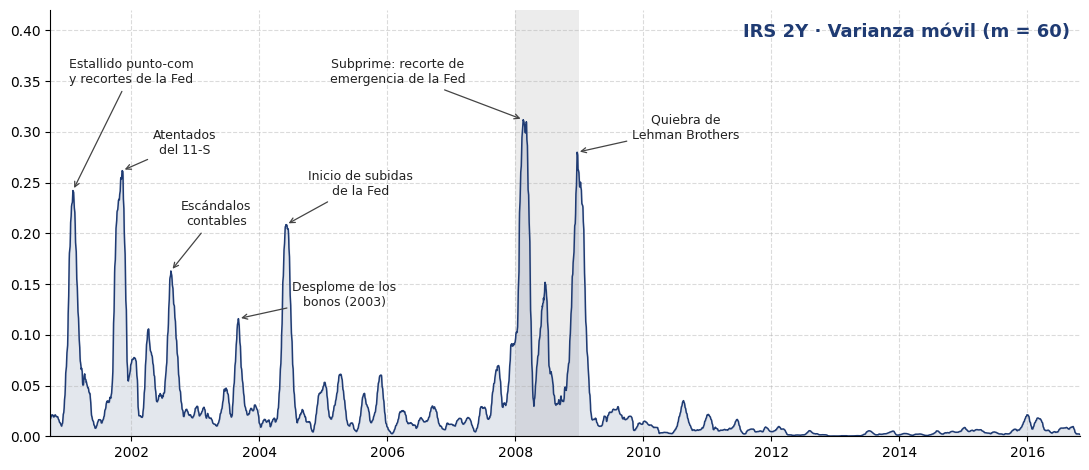

In [ ]:
# Figura 6.2: varianza del IRS 2Y con los episodios señalados
v = varianza_movil(irs).dropna()
eventos = [('2001-02-01', 'Estallido punto-com\ny recortes de la Fed', ('2002-01-01', 0.345)),
           ('2001-11-09', 'Atentados\ndel 11-S',                         ('2002-11-01', 0.275)),
           ('2002-08-14', 'Escándalos\ncontables',                        ('2003-05-01', 0.205)),
           ('2003-09-03', 'Desplome de los\nbonos (2003)',                ('2005-05-01', 0.125)),
           ('2004-06-02', 'Inicio de subidas\nde la Fed',                 ('2005-08-01', 0.235)),
           ('2008-02-15', 'Subprime: recorte de\nemergencia de la Fed',   ('2006-03-01', 0.345)),
           ('2008-12-19', 'Quiebra de\nLehman Brothers',                  ('2010-09-01', 0.29))]

fig, ax = plt.subplots(figsize=(11, 4.8))
banda_2008(ax)
ax.plot(v.index, v.values, color=AZUL, lw=1.1)
ax.fill_between(v.index, v.values, 0, color=AZUL, alpha=0.12)
for fecha, texto, (x_txt, y_txt) in eventos:
    fecha = pd.Timestamp(fecha)
    ax.annotate(texto, xy=(fecha, v.loc[fecha]), xytext=(pd.Timestamp(x_txt), y_txt),
                fontsize=9, ha='center', va='bottom', color='#222',
                arrowprops=dict(arrowstyle='->', color='#444', lw=0.9, shrinkA=2, shrinkB=2))
ax.set_ylim(0, 0.42); ax.set_xlim(v.index[0], v.index[-1]); formato(ax)
ax.text(0.99, 0.97, 'IRS 2Y · Varianza móvil (m = 60)', transform=ax.transAxes, fontsize=13,
        fontweight='bold', color=AZUL, va='top', ha='right')
fig.tight_layout(); guardar(fig, 'rolling_variance_irs2y_eventos.png')

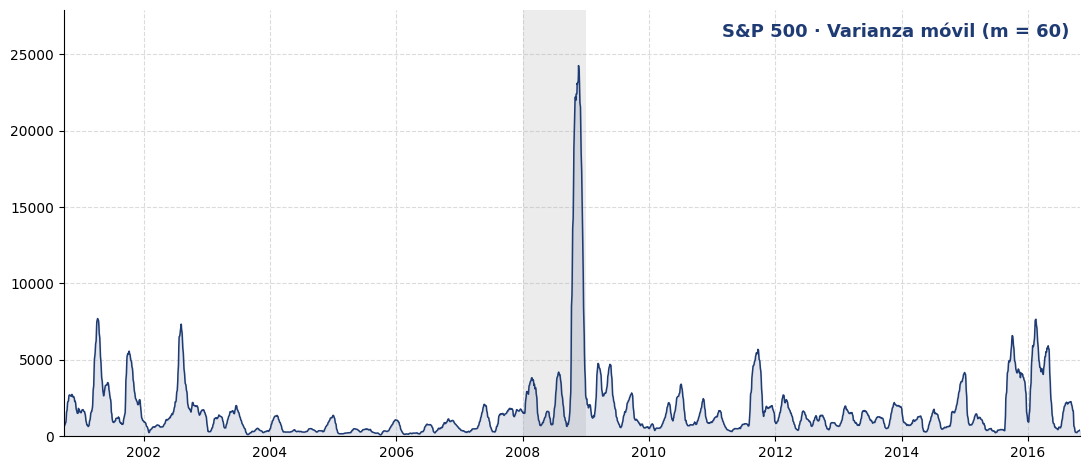

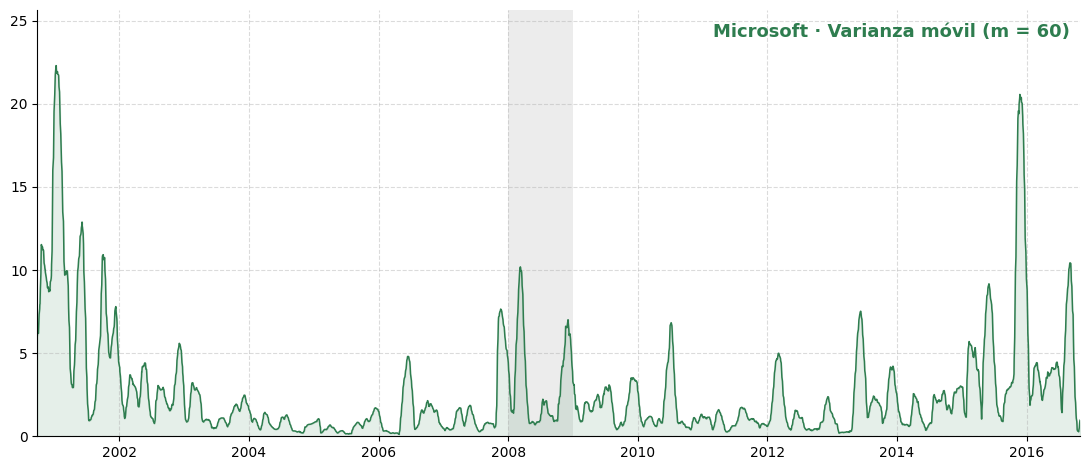

In [ ]:
# Figuras 6.3 y 6.4: varianza del S&P 500 y de Microsoft
for s, nombre, color, fichero in [(sp, 'S&P 500', AZUL, 'rolling_variance_sp500.png'),
                                  (msft, 'Microsoft', VERDE, 'rolling_variance_msft.png')]:
    v = varianza_movil(s).dropna()
    fig, ax = plt.subplots(figsize=(11, 4.8))
    banda_2008(ax)
    ax.plot(v.index, v.values, color=color, lw=1.1)
    ax.fill_between(v.index, v.values, 0, color=color, alpha=0.12)
    ax.set_ylim(0, v.max() * 1.15); ax.set_xlim(v.index[0], v.index[-1]); formato(ax)
    ax.text(0.99, 0.97, f'{nombre} · Varianza móvil (m = 60)', transform=ax.transAxes, fontsize=13,
            fontweight='bold', color=color, va='top', ha='right')
    fig.tight_layout(); guardar(fig, fichero)

In [ ]:
# Tabla 6.2: máximos de la varianza en la época punto-com (2000-2003) y en la crisis (2007-2009)
filas = {}
for nombre, s in [('S&P 500', sp), ('Citigroup', citi), ('Microsoft', msft)]:
    v = varianza_movil(s)
    dot, leh = v['2000':'2003'], v['2007':'2009']
    filas[nombre] = {'Máximo Dot-Com': dot.idxmax().strftime('%Y-%m'),
                     'Máximo Lehman': leh.idxmax().strftime('%Y-%m'),
                     'Cociente': round(leh.max() / dot.max(), 2)}
print(pd.DataFrame(filas).T)

# Nivel de cotización de Microsoft (efecto de escala del pico de 2015)
print('\nMicrosoft, precio medio oct 2000-ene 2001:', round(msft['2000-10':'2001-01'].mean(), 1))
print('Microsoft, precio medio sep-nov 2015     :', round(msft['2015-09':'2015-11'].mean(), 1))
print('Mayor variación diaria sep-nov 2015      :', msft.pct_change()['2015-09':'2015-11'].abs().idxmax().date())

          Máximo Dot-Com Máximo Lehman Cociente
S&P 500          2001-04       2008-11     3.15
Citigroup        2002-08       2007-12     1.66
Microsoft        2001-01       2008-03     0.46

Microsoft, precio medio oct 2000-ene 2001: 29.2
Microsoft, precio medio sep-nov 2015     : 48.6
Mayor variación diaria sep-nov 2015      : 2015-10-23


### 5.3 Autocorrelación

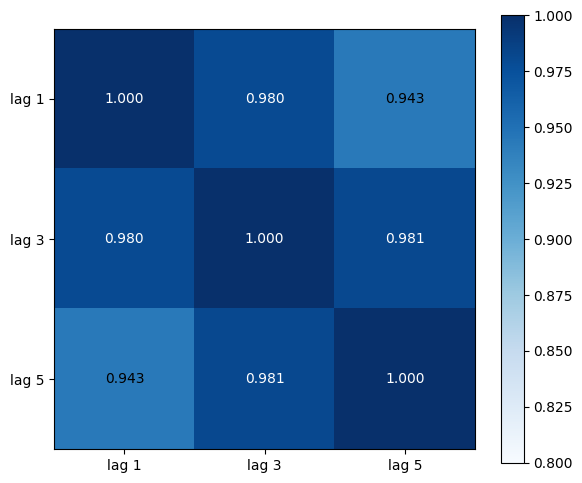

           Lags 1 y 3  Lags 1 y 5  Lags 3 y 5
S&P 500         0.936       0.888       0.971
Citigroup       0.980       0.943       0.981
Microsoft       0.932       0.889       0.979
IRS 2Y          0.974       0.918       0.960


In [ ]:
# Figura 6.5 y Tabla 6.3: correlación entre las autocorrelaciones con lags 1, 3 y 5 (2008-2009)
tabla_lags = {}
for nombre, s in [('S&P 500', sp), ('Citigroup', citi), ('Microsoft', msft), ('IRS 2Y', irs)]:
    ac = pd.DataFrame({f'lag {k}': autocorr_movil(s, 60, k) for k in (1, 3, 5)})['2008-01-01':'2009-12-31']
    c = ac.corr()
    tabla_lags[nombre] = {'Lags 1 y 3': c.iloc[0, 1], 'Lags 1 y 5': c.iloc[0, 2], 'Lags 3 y 5': c.iloc[1, 2]}
    if nombre == 'Citigroup':
        fig, ax = plt.subplots(figsize=(6, 5))
        im = ax.imshow(c.values, cmap='Blues', vmin=0.8, vmax=1)
        ax.set_xticks(range(3)); ax.set_yticks(range(3))
        ax.set_xticklabels(c.columns); ax.set_yticklabels(c.columns)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, f'{c.values[i, j]:.3f}', ha='center', va='center',
                        color='white' if c.values[i, j] > 0.95 else 'black')
        fig.colorbar(im, ax=ax); fig.tight_layout(); guardar(fig, 'matriz_citigroup.png')
print(pd.DataFrame(tabla_lags).T.round(3))

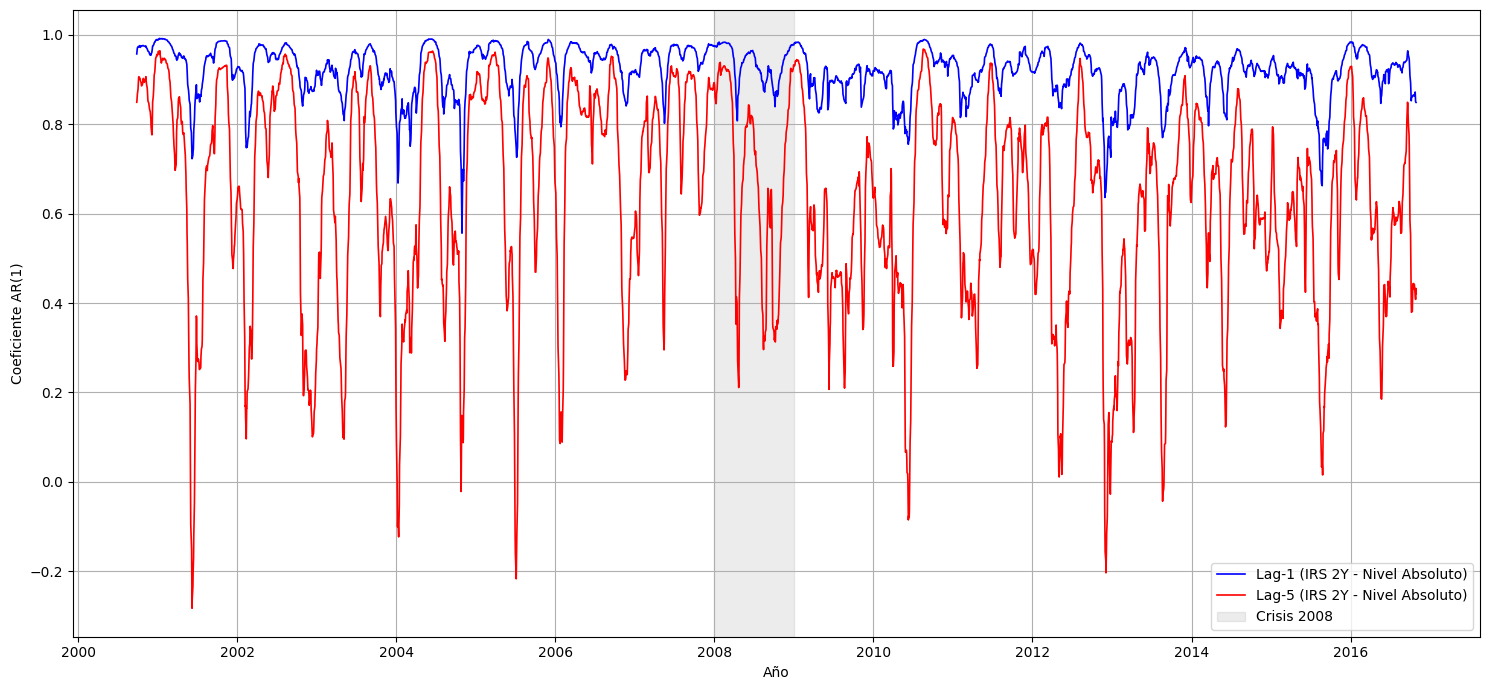

Mediana lag 1: 0.93 | mediana lag 5: 0.675 | % días con lag 5 < lag 1: 98.6


In [ ]:
# Figura 6.6: lags 1 y 5 del IRS 2Y
ac1, ac5 = autocorr_movil(irs, 60, 1), autocorr_movil(irs, 60, 5)
fig, ax = plt.subplots(figsize=(15, 7))
ax.plot(ac1.index, ac1.values, color='blue', lw=1.2, label='Lag-1 (IRS 2Y - Nivel Absoluto)')
ax.plot(ac5.index, ac5.values, color='red', lw=1.2, label='Lag-5 (IRS 2Y - Nivel Absoluto)')
ax.axvspan(pd.Timestamp('2008-01-01'), pd.Timestamp('2008-12-31'), color='gray', alpha=0.15, label='Crisis 2008')
ax.set_xlabel('Año'); ax.set_ylabel('Coeficiente AR(1)')
ax.grid(True); ax.legend(loc='lower right')
fig.tight_layout(); guardar(fig, 'autocorrcomp_irs2y.png', dpi=100)
print('Mediana lag 1:', round(ac1.median(), 3), '| mediana lag 5:', round(ac5.median(), 3),
      '| % días con lag 5 < lag 1:', round(100 * (ac5 < ac1).mean(), 1))

S&P 500    mínimo 0.59 (2015-06-29)  % por encima de 0.85: 87%
Citigroup  mínimo 0.61 (2007-10-16)  % por encima de 0.85: 87%
Microsoft  mínimo 0.44 (2006-04-28)  % por encima de 0.85: 83%


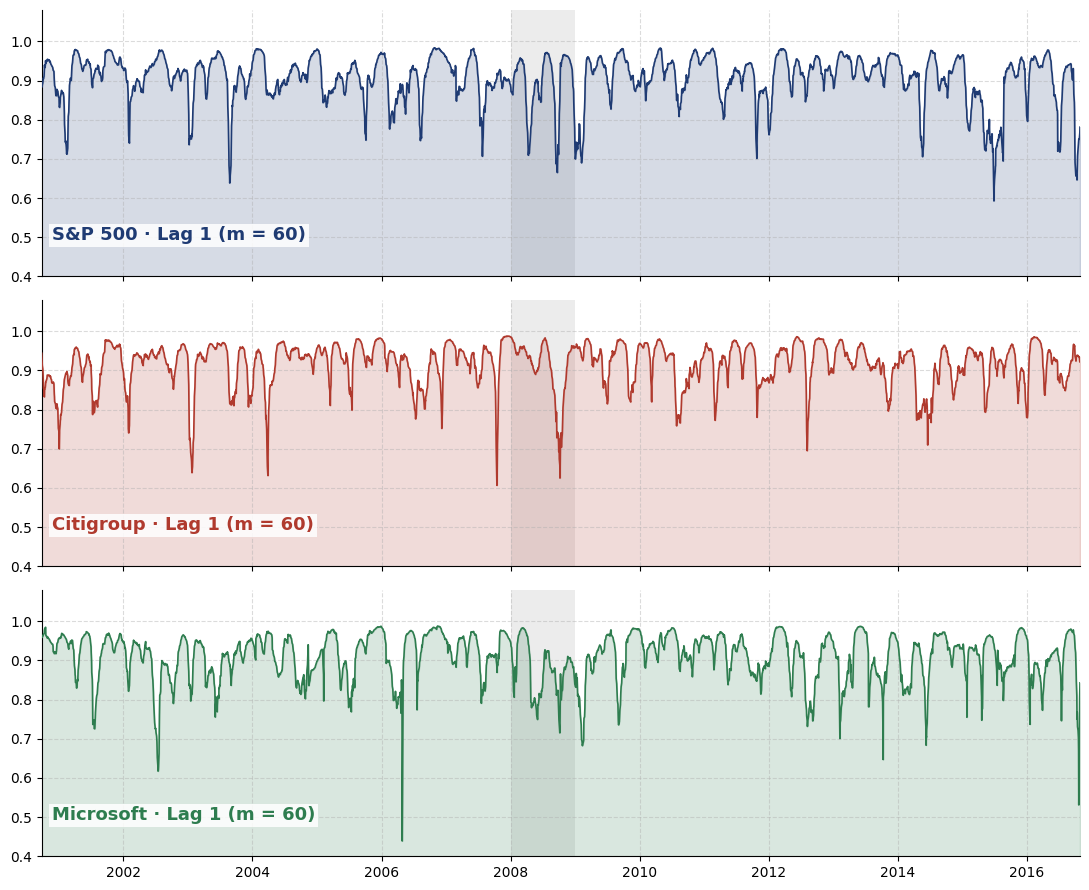

In [ ]:
# Figura 6.7: lag 1 de las tres series de renta variable
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True)
for ax, (nombre, s, color) in zip(axes, acciones):
    a = autocorr_movil(s).dropna()
    banda_2008(ax)
    ax.fill_between(a.index, a.values, 0.4, color=color, alpha=0.18, zorder=1)
    ax.plot(a.index, a.values, color=color, lw=1.2, zorder=3)
    ax.set_ylim(0.4, 1.08)
    ax.text(0.01, 0.12, f'{nombre} · Lag 1 (m = 60)', transform=ax.transAxes, fontsize=13, fontweight='bold',
            color=color, va='bottom', zorder=5, bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2))
    formato(ax)
    print(f'{nombre:10s} mínimo {a.min():.2f} ({a.idxmin().date()})  % por encima de 0.85: {100 * (a > 0.85).mean():.0f}%')
axes[-1].set_xlim(a.index[0], sp.index[-1])
fig.tight_layout(); guardar(fig, 'tres_series_lag1.png')

### 5.4 Sesgo

In [ ]:
# Tabla 6.4: correlación entre los sesgos con ventanas de 60, 90 y 120 sesiones (2000-2016)
tabla_sesgo = {}
for nombre, s in [('S&P 500', sp), ('Citigroup', citi), ('Microsoft', msft), ('IRS 2Y', irs)]:
    c = pd.DataFrame({m: sesgo_movil(s, m) for m in (60, 90, 120)}).dropna().corr()
    tabla_sesgo[nombre] = {'60-90': c.loc[60, 90], '90-120': c.loc[90, 120], '60-120': c.loc[60, 120]}
print(pd.DataFrame(tabla_sesgo).T.round(2))

           60-90  90-120  60-120
S&P 500     0.47    0.63    0.26
Citigroup   0.54    0.67    0.32
Microsoft   0.58    0.71    0.34
IRS 2Y      0.48    0.59    0.21


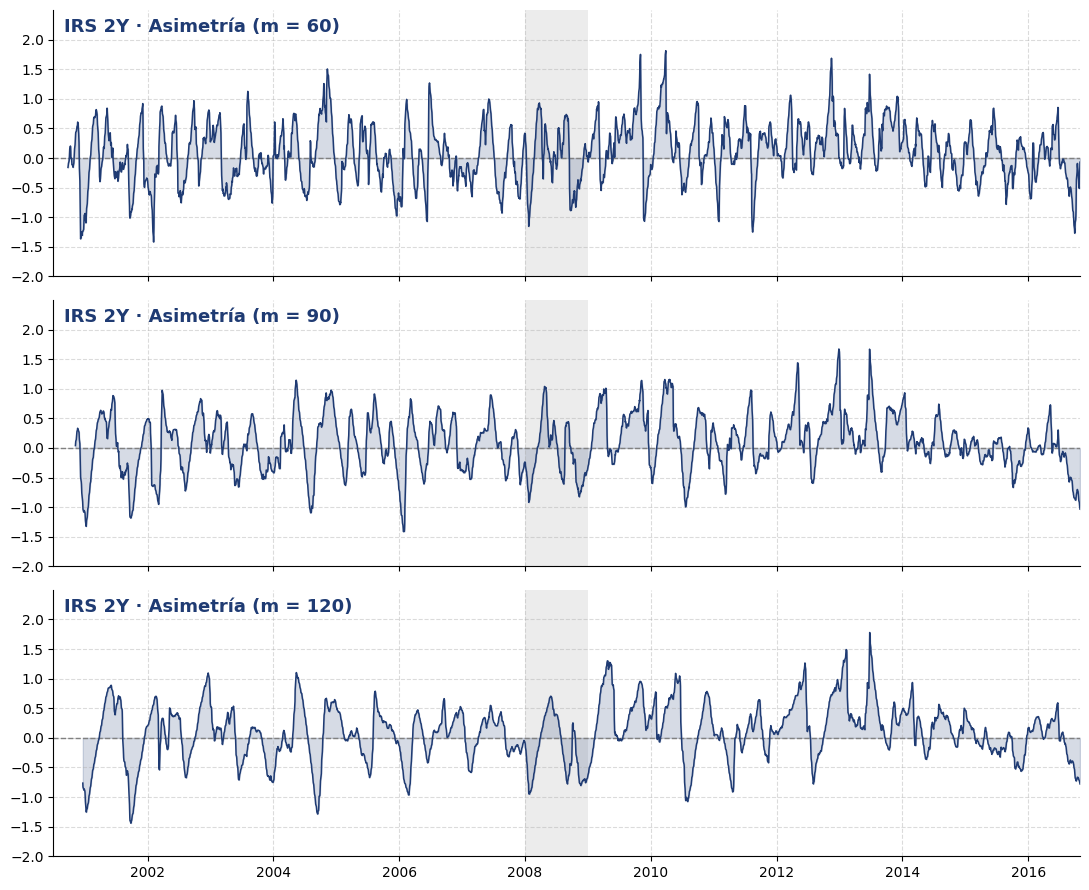

In [ ]:
# Figura 6.8: sesgo del IRS 2Y con ventanas de 60, 90 y 120 sesiones
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True)
for ax, m in zip(axes, (60, 90, 120)):
    v = sesgo_movil(irs, m).dropna()
    banda_2008(ax)
    ax.fill_between(v.index, v.values, 0, color=AZUL, alpha=0.18, zorder=1)
    ax.plot(v.index, v.values, color=AZUL, lw=1.1, zorder=3)
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.set_ylim(-2, 2.5); ax.set_yticks(np.arange(-2, 2.01, 0.5))
    ax.text(0.01, 0.97, f'IRS 2Y · Asimetría (m = {m})', transform=ax.transAxes, fontsize=13,
            fontweight='bold', color=AZUL, va='top', zorder=5)
    formato(ax)
axes[-1].set_xlim(irs.index[0], irs.index[-1])
fig.tight_layout(); guardar(fig, 'sesgos_irs2y.png')

S&P 500    mínimo -3.34 (2015-08-24)  máximo 1.24 (2008-12-18)
Citigroup  mínimo -2.22 (2003-01-03)  máximo 2.43 (2006-12-18)
Microsoft  mínimo -3.35 (2006-04-28)  máximo 2.45 (2005-02-07)


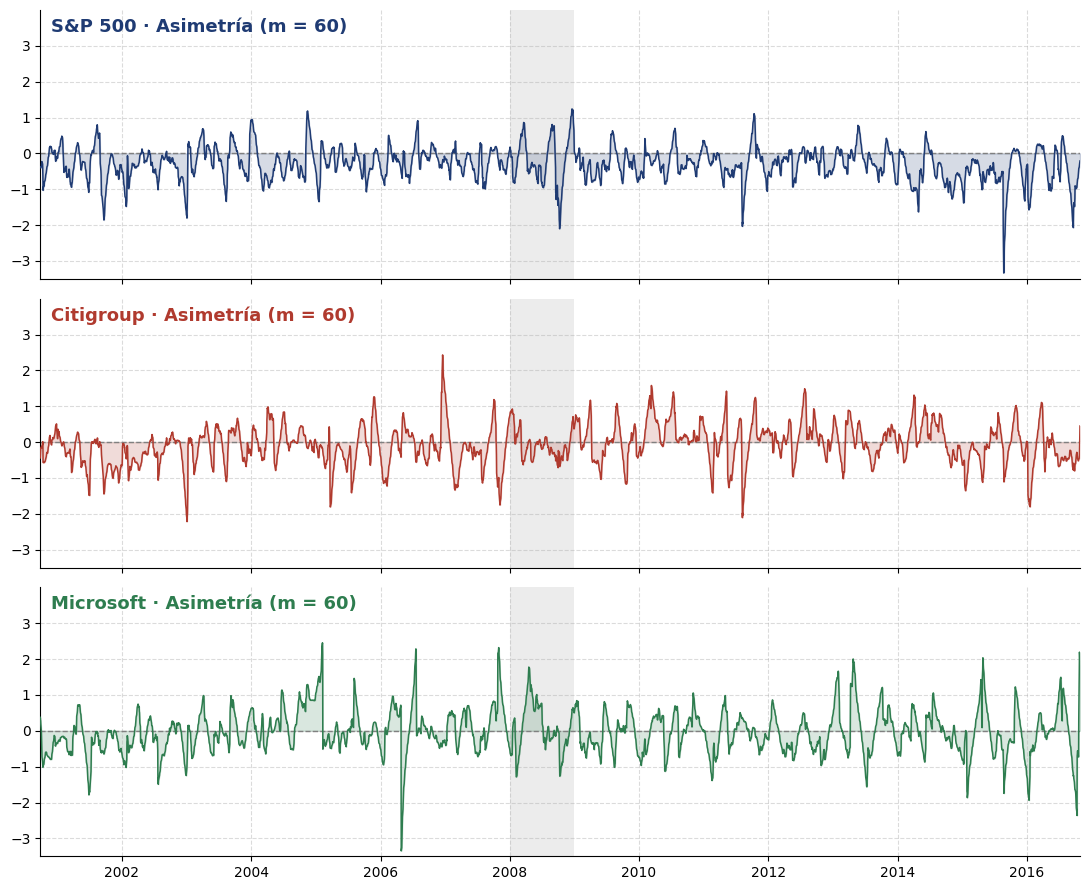

In [ ]:
# Figura 6.9: sesgo de las tres series de renta variable (m = 60)
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True)
for ax, (nombre, s, color) in zip(axes, acciones):
    v = sesgo_movil(s).dropna()
    banda_2008(ax)
    ax.fill_between(v.index, v.values, 0, color=color, alpha=0.18, zorder=1)
    ax.plot(v.index, v.values, color=color, lw=1.1, zorder=3)
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.set_ylim(-3.5, 4); ax.set_yticks(np.arange(-3, 3.01, 1))
    ax.text(0.01, 0.97, f'{nombre} · Asimetría (m = 60)', transform=ax.transAxes, fontsize=13,
            fontweight='bold', color=color, va='top', zorder=5)
    formato(ax)
    print(f'{nombre:10s} mínimo {v.min():.2f} ({v.idxmin().date()})  máximo {v.max():.2f} ({v.idxmax().date()})')
axes[-1].set_xlim(v.index[0], sp.index[-1])
fig.tight_layout(); guardar(fig, 'tres_series_sesgo.png')

## 6. Resultados: indicadores sobre los residuos

Las series se truncan **antes** de aplicar el filtro gaussiano (σ = 30), ya que al ser bilateral
los datos posteriores a la quiebra influirían en la tendencia estimada antes de ella.
En las acciones el filtro se aplica sobre `100·log(precio)` (residuos en %); en el IRS 2Y,
sobre el tipo de interés directamente.

In [ ]:
SIGMA = 30
INICIO = '2004-01-01'

def descomponer(s, sigma=SIGMA, usar_log=True):
    """Devuelve (tendencia, residuos). Con usar_log=True, la tendencia se estima sobre
    100·log(s) y los residuos son desviaciones porcentuales respecto a ella."""
    y = np.log(s) * 100 if usar_log else s.astype(float)
    tendencia = pd.Series(gaussian_filter1d(y.values, sigma), index=s.index)
    return tendencia, y - tendencia

def residuos(s, usar_log=True, inicio=INICIO, fin=ULTIMO_DIA, sigma=SIGMA):
    return descomponer(s[inicio:fin], sigma, usar_log)[1]

activos = {'S&P 500': (sp, True, AZUL), 'Citigroup': (citi, True, ROJO),
           'Microsoft': (msft, True, VERDE), 'IRS 2Y': (irs, False, AZUL)}
RES = {nombre: residuos(s, log) for nombre, (s, log, _) in activos.items()}

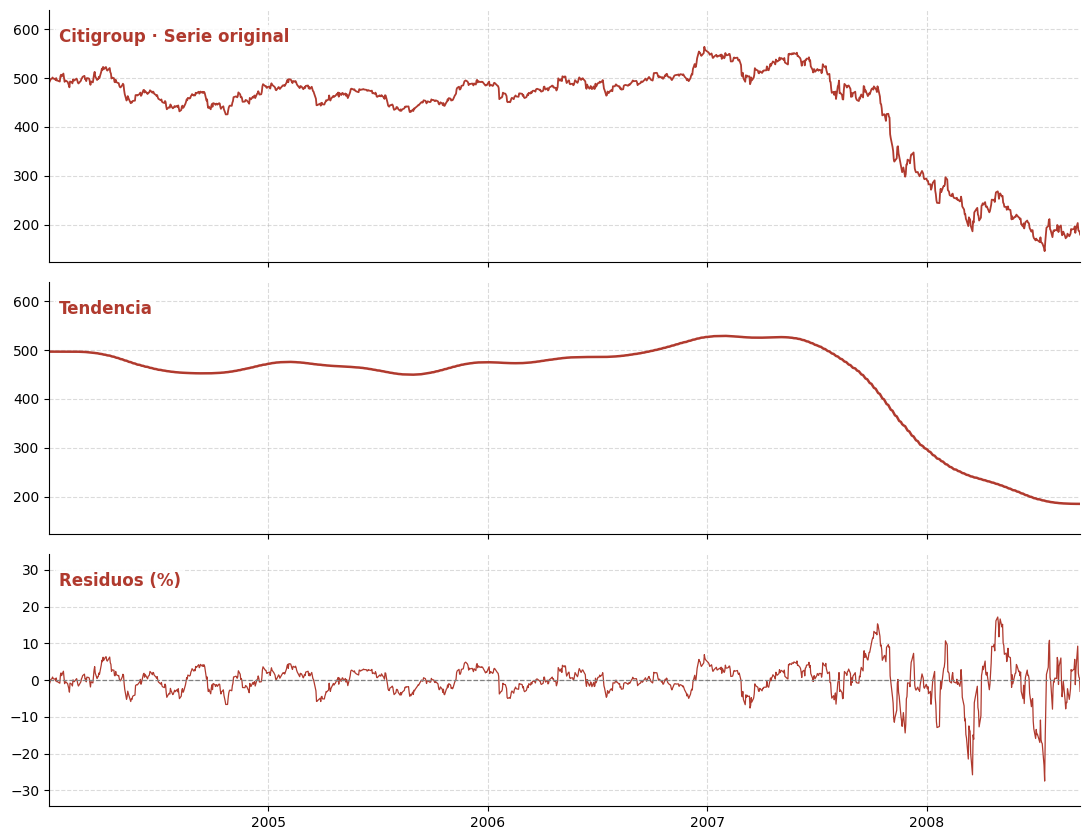

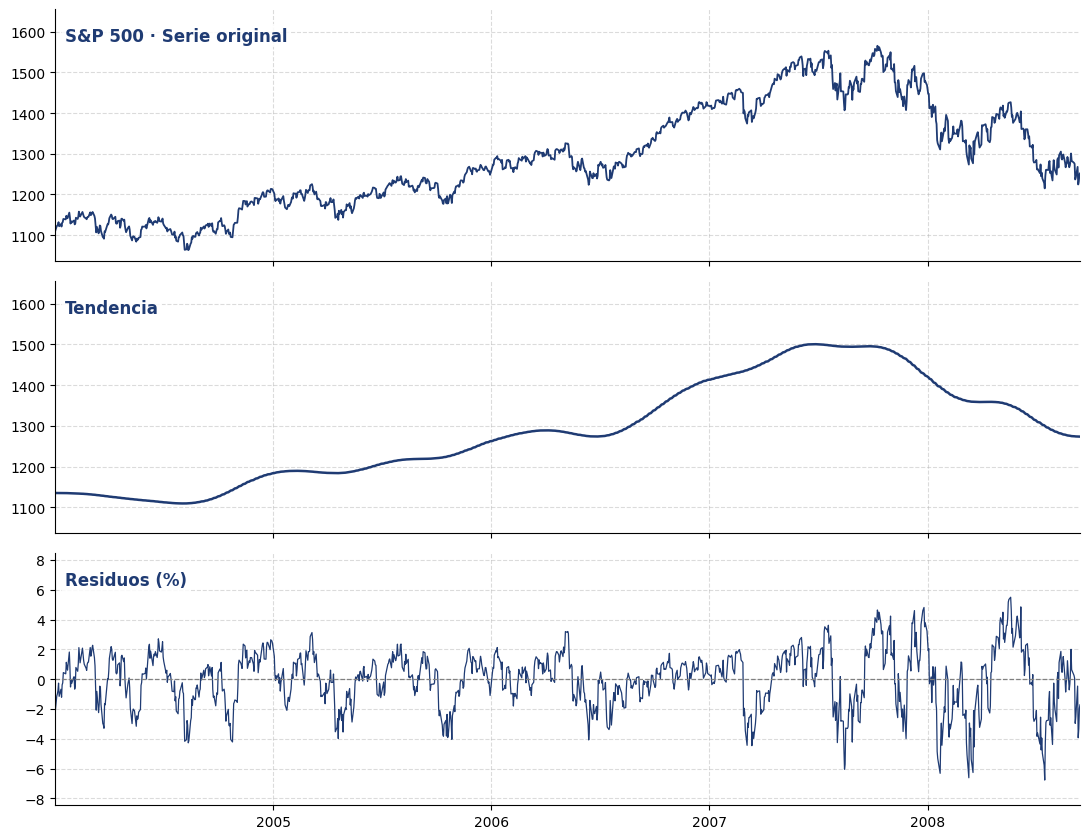

In [ ]:
# Figura de la metodología: descomposición de Citigroup (precio, tendencia y residuos)
def figura_descomposicion(nombre, s, color, usar_log, fichero):
    seg = s[INICIO:ULTIMO_DIA]
    tend, res = descomponer(seg, usar_log=usar_log)
    if usar_log:
        tend = np.exp(tend / 100)                 # tendencia en unidades de precio
    fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
    datos = [(seg, f'{nombre} · Serie original', 1.3), (tend, 'Tendencia', 1.8),
             (res, 'Residuos (%)' if usar_log else 'Residuos (p.p.)', 0.9)]
    for ax, (serie, etiqueta, grosor) in zip(axes, datos):
        ax.plot(serie.index, serie.values, color=color, lw=grosor)
        ax.text(0.01, 0.93, etiqueta, transform=ax.transAxes, fontsize=12, fontweight='bold', color=color,
                va='top', zorder=5, bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2))
        formato(ax, 1)
    axes[2].axhline(0, color='grey', lw=0.9, ls='--')
    lo, hi = min(seg.min(), tend.min()), max(seg.max(), tend.max()); pad = (hi - lo) * 0.18
    for ax in axes[:2]: ax.set_ylim(lo - pad * 0.3, hi + pad)
    lim = res.abs().max() * 1.25; axes[2].set_ylim(-lim, lim)
    axes[-1].set_xlim(seg.index[0], seg.index[-1])
    fig.tight_layout(); guardar(fig, fichero)

figura_descomposicion('Citigroup', citi, ROJO, True, 'descomposicion_citigroup.png')
figura_descomposicion('S&P 500', sp, AZUL, True, 'descomposicion_sp500.png')

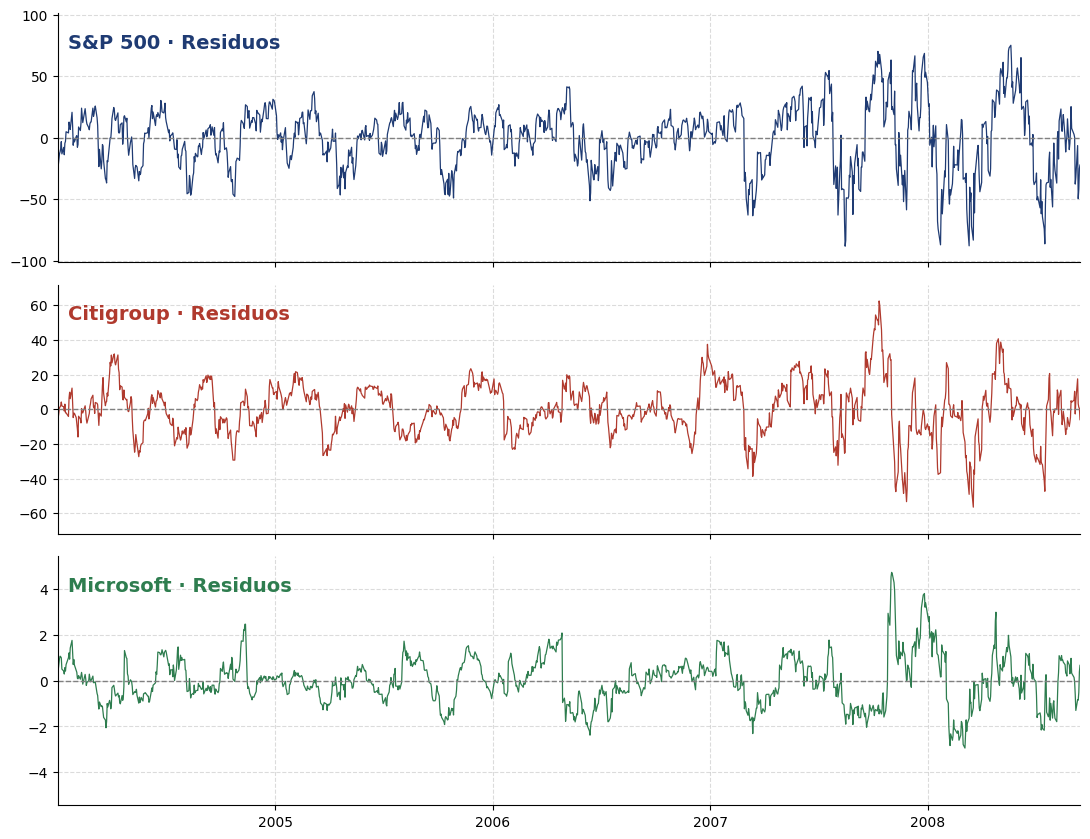

S&P 500    precio medio   1289.0  residuo máximo   88.1  (7% del precio)
Citigroup  precio medio    437.9  residuo máximo   62.5  (14% del precio)
Microsoft  precio medio     27.6  residuo máximo    4.7  (17% del precio)


In [ ]:
# Figura: residuos de los precios SIN logaritmos (cada panel con su propia escala)
def figura_residuos(lista, fichero, usar_log, eje_comun=None, sufijo='Residuos'):
    fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
    for ax, (nombre, s, color) in zip(axes, lista):
        r = residuos(s, usar_log)
        ax.plot(r.index, r.values, color=color, lw=0.9)
        ax.axhline(0, color='gray', ls='--', lw=1)
        if eje_comun is None:
            lim = r.abs().max() * 1.15; ax.set_ylim(-lim, lim)
        else:
            ax.set_ylim(-eje_comun, eje_comun)
        ax.text(0.01, 0.92, f'{nombre} · {sufijo}', transform=ax.transAxes, fontsize=14,
                fontweight='bold', color=color, va='top')
        formato(ax, 1)
    axes[-1].set_xlim(r.index[0], r.index[-1])
    fig.tight_layout(); guardar(fig, fichero)

figura_residuos(acciones, 'residuos_acciones.png', usar_log=False)
for nombre, s, _ in acciones:
    r, nivel = residuos(s, False), s[INICIO:ULTIMO_DIA].mean()
    print(f'{nombre:10s} precio medio {nivel:8.1f}  residuo máximo {r.abs().max():6.1f}  ({100 * r.abs().max() / nivel:.0f}% del precio)')

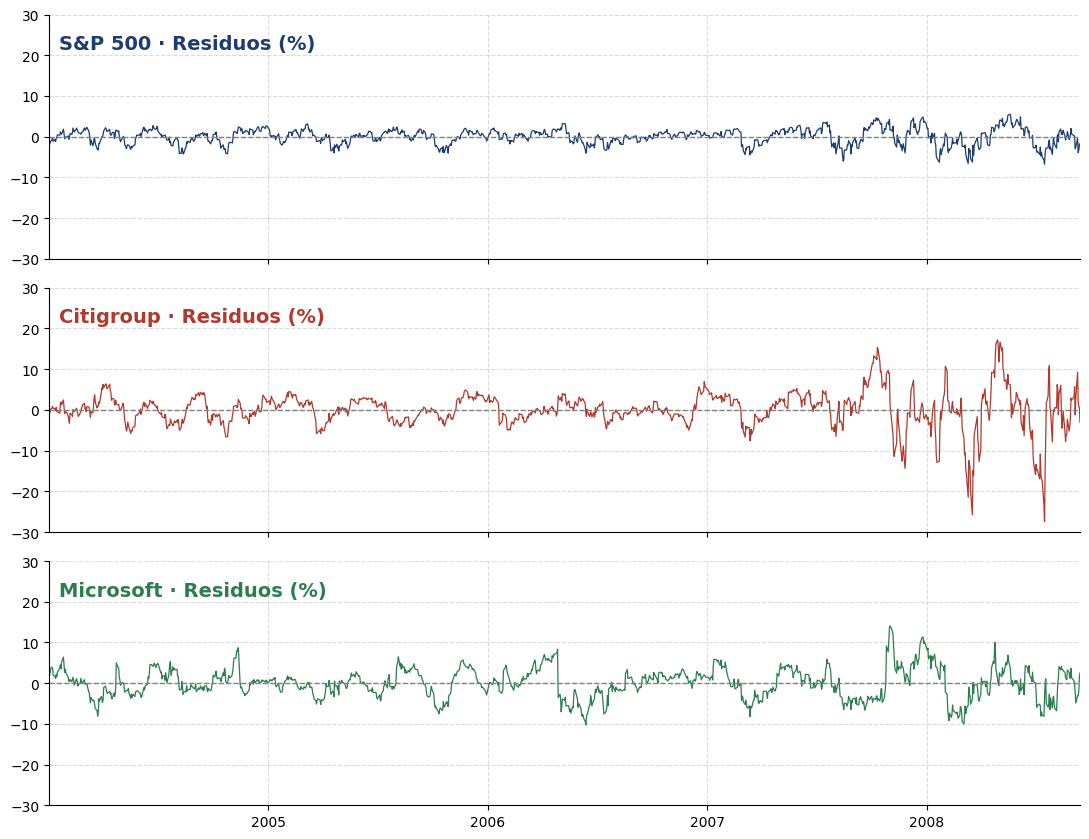

precio 525, tendencia 500: residuo 25 $  |  log: 4.9 %
precio 165, tendencia 150: residuo 15 $  |  log: 9.5 %


In [ ]:
# Figura: residuos de los logaritmos (eje común, de -30 % a 30 %)
figura_residuos(acciones, 'residuos_log_acciones.png', usar_log=True, eje_comun=30, sufijo='Residuos (%)')

# Ejemplo del texto: residuos sobre precios frente a residuos logarítmicos
for x, t in [(525, 500), (165, 150)]:
    print(f'precio {x}, tendencia {t}: residuo {x - t} $  |  log: {100 * np.log(x / t):.1f} %')

### 6.1 Varianza de los residuos

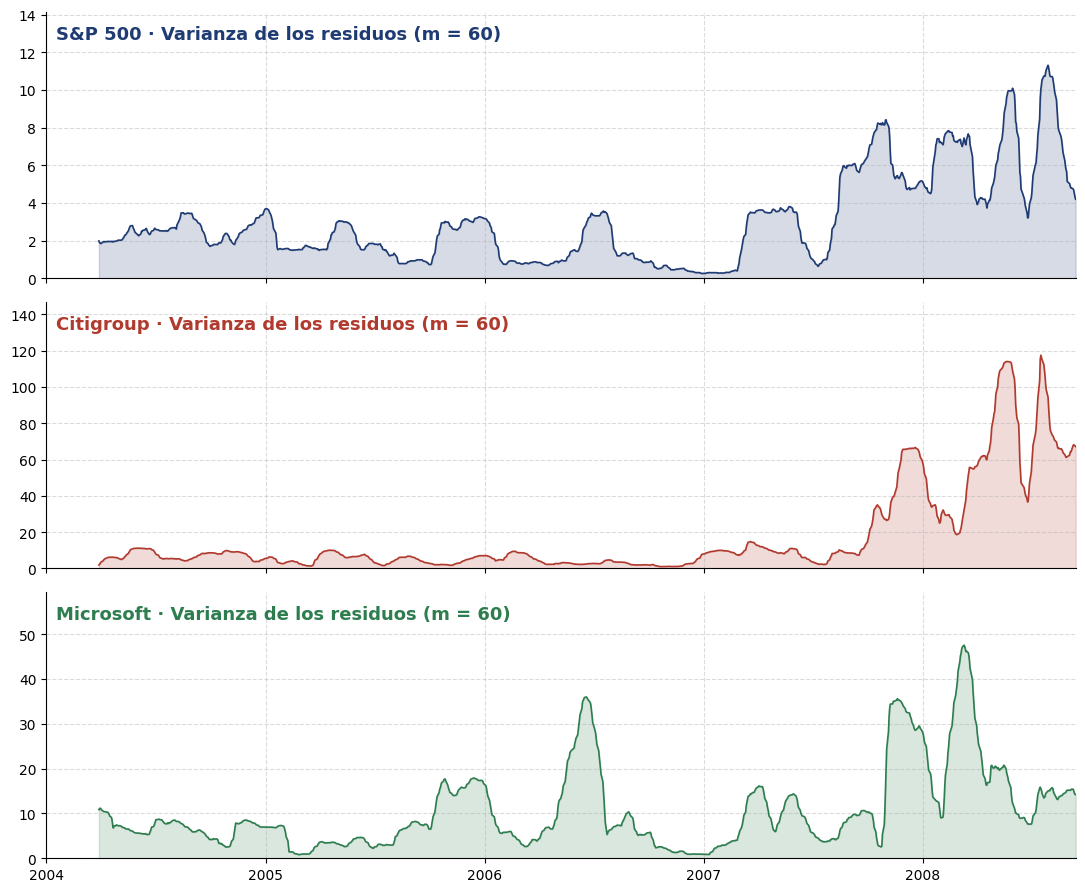

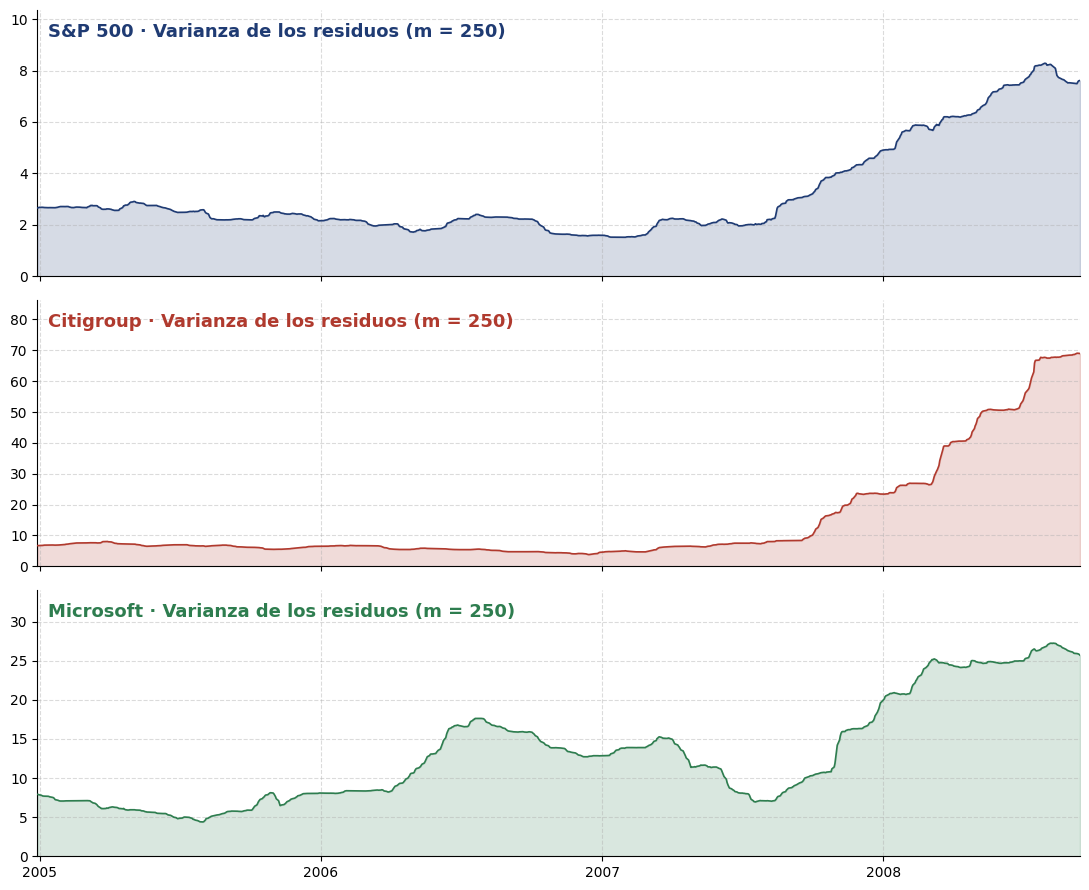


m = 60
  S&P 500    media calma    1.74  máximo   11.31 (2008-07-28)
  Citigroup  media calma    5.23  máximo  117.49 (2008-07-16)
  Microsoft  media calma    8.24  máximo   47.56 (2008-03-10)
  IRS 2Y     media calma    0.01  máximo    0.08 (2008-03-05)

m = 250
  S&P 500    media calma    2.20  máximo    8.28 (2008-07-28)
  Citigroup  media calma    6.06  máximo   69.07 (2008-09-09)
  Microsoft  media calma   10.18  máximo   27.26 (2008-08-08)
  IRS 2Y     media calma    0.01  máximo    0.06 (2008-06-26)


In [ ]:
def figura_indicador_residuos(funcion, m, fichero, titulo, lim_y=None, texto_abajo=False):
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=lim_y is not None)
    for ax, (nombre, s, color) in zip(axes, acciones):
        v = funcion(RES[nombre], m).dropna()
        base = lim_y[0] if lim_y else 0
        ax.fill_between(v.index, v.values, base, color=color, alpha=0.18, zorder=1)
        ax.plot(v.index, v.values, color=color, lw=1.2, zorder=3)
        ax.set_ylim(*(lim_y if lim_y else (0, v.max() * 1.25)))
        if texto_abajo:
            ax.text(0.01, 0.06, f'{nombre} · {titulo} (m = {m})', transform=ax.transAxes, fontsize=13,
                    fontweight='bold', color=color, va='bottom', zorder=5,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2))
        else:
            ax.text(0.01, 0.95, f'{nombre} · {titulo} (m = {m})', transform=ax.transAxes, fontsize=13,
                    fontweight='bold', color=color, va='top', zorder=5)
        formato(ax, 1)
    axes[-1].set_xlim(v.index[0] if m == 250 else pd.Timestamp(INICIO), pd.Timestamp(ULTIMO_DIA))
    fig.tight_layout(); guardar(fig, fichero)

figura_indicador_residuos(varianza_movil, 60, 'varianza_residuos_acciones.png', 'Varianza de los residuos')
figura_indicador_residuos(varianza_movil, 250, 'varianza_residuos_acciones_250.png', 'Varianza de los residuos')

for m in (60, 250):
    print(f'\nm = {m}')
    for nombre in RES:
        v = varianza_movil(RES[nombre], m).dropna()
        print(f'  {nombre:10s} media calma {v[CALMA].mean():7.2f}  máximo {v.max():7.2f} ({v.idxmax().date()})')

### 6.2 Autocorrelación de los residuos

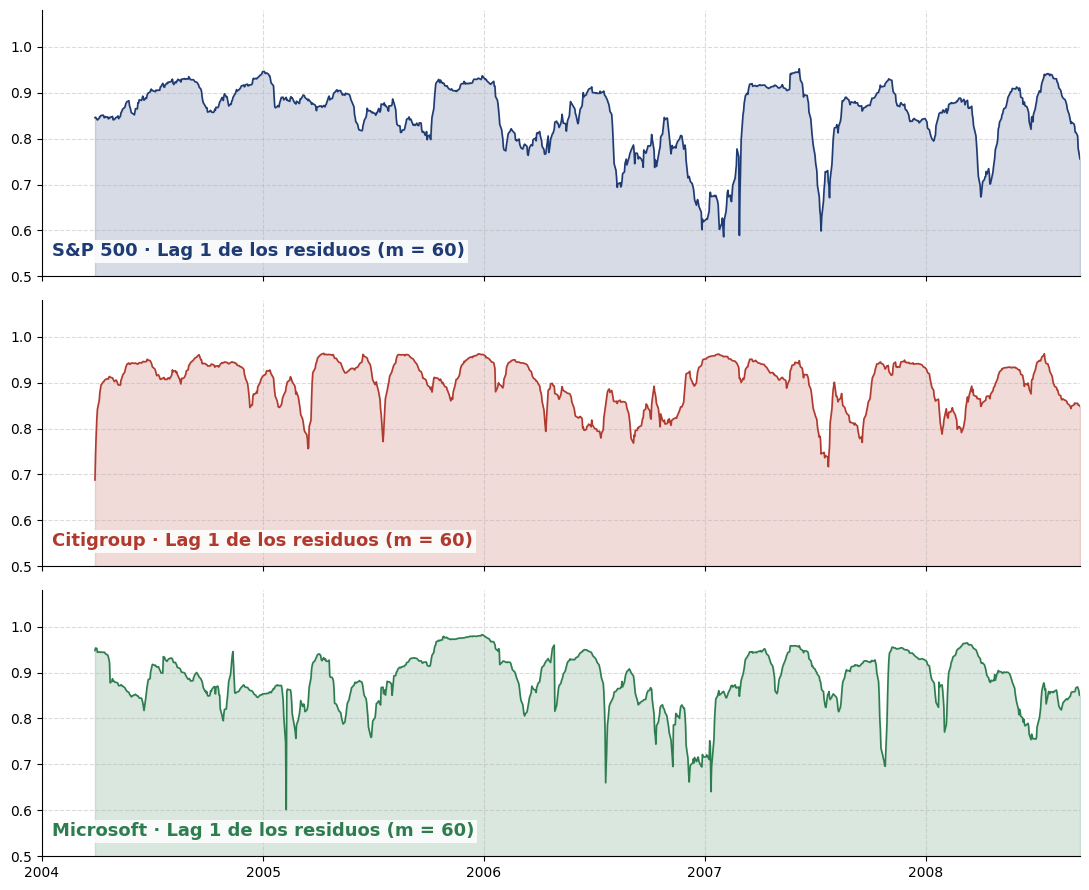

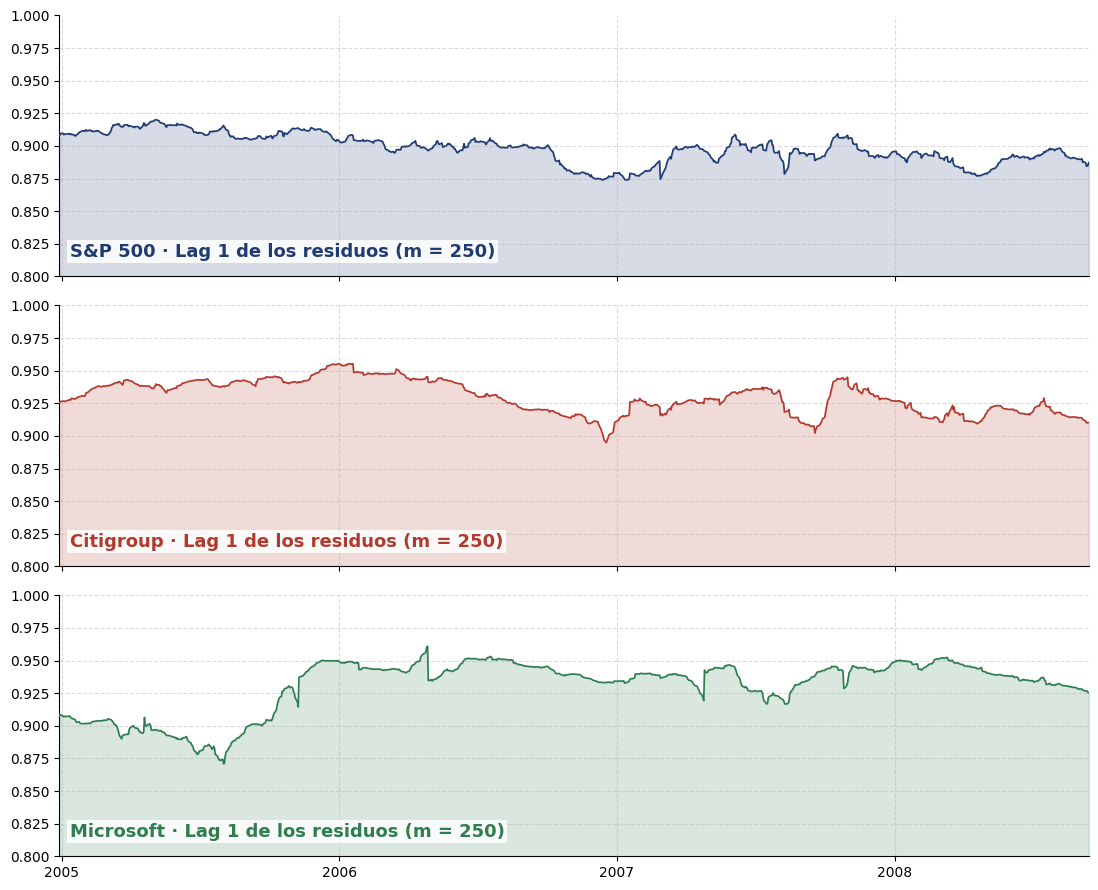

           m = 60  m = 250
S&P 500     0.586    0.874
Citigroup   0.717    0.895
Microsoft   0.602    0.871

m = 60: media del lag 1 en calma y antes de la quiebra
  S&P 500    mediana 0.871  calma 0.839  pre-crisis 0.848
  Citigroup  mediana 0.910  calma 0.899  pre-crisis 0.879
  Microsoft  mediana 0.883  calma 0.882  pre-crisis 0.882
  IRS 2Y     mediana 0.910  calma 0.897  pre-crisis 0.888

m = 250: media del lag 1 en calma y antes de la quiebra
  S&P 500    mediana 0.899  calma 0.901  pre-crisis 0.892
  Citigroup  mediana 0.930  calma 0.934  pre-crisis 0.922
  Microsoft  mediana 0.939  calma 0.927  pre-crisis 0.938
  IRS 2Y     mediana 0.934  calma 0.933  pre-crisis 0.936


In [ ]:
figura_indicador_residuos(autocorr_movil, 60, 'lag1_residuos_acciones.png', 'Lag 1 de los residuos',
                          lim_y=(0.5, 1.08), texto_abajo=True)
figura_indicador_residuos(autocorr_movil, 250, 'lag1_residuos_acciones_250.png', 'Lag 1 de los residuos',
                          lim_y=(0.8, 1.0), texto_abajo=True)

# Tabla 6.5: mínimos del lag 1 de los residuos logarítmicos
# (con m = 60 se descarta la primera ventana, afectada por el borde del filtro)
minimos = {}
for nombre, *_ in acciones:
    a60  = autocorr_movil(RES[nombre], 60).dropna().iloc[5:]
    a250 = autocorr_movil(RES[nombre], 250).dropna()
    minimos[nombre] = {'m = 60': a60.min(), 'm = 250': a250.min()}
print(pd.DataFrame(minimos).T.round(3))

for m in (60, 250):
    print(f'\nm = {m}: media del lag 1 en calma y antes de la quiebra')
    for nombre in RES:
        a = autocorr_movil(RES[nombre], m).dropna()
        print(f'  {nombre:10s} mediana {a.median():.3f}  calma {a[CALMA].mean():.3f}  pre-crisis {a[PRE].mean():.3f}')

In [ ]:
# Autocorrelación de un paseo aleatorio filtrado (y de ruido blanco), según σ
rng = np.random.default_rng(0)
for sigma in (5, 10, 30, 60):
    paseo, ruido = [], []
    for _ in range(200):
        x = np.cumsum(rng.normal(size=1200))
        paseo.append(pd.Series((x - gaussian_filter1d(x, sigma))[100:-100]).autocorr(1))
        x = rng.normal(size=1200)
        ruido.append(pd.Series((x - gaussian_filter1d(x, sigma))[100:-100]).autocorr(1))
    print(f'σ = {sigma:2d}: paseo aleatorio {np.mean(paseo):.3f} | ruido blanco {np.mean(ruido):.3f}')

σ =  5: paseo aleatorio 0.611 | ruido blanco -0.114
σ = 10: paseo aleatorio 0.794 | ruido blanco -0.054
σ = 30: paseo aleatorio 0.928 | ruido blanco -0.017
σ = 60: paseo aleatorio 0.962 | ruido blanco -0.008


### 6.3 Comparación entre activos (Tabla 6.6)

Para cada activo: ratio entre la varianza media antes de la quiebra y en calma, porcentaje de días
previos a la quiebra con varianza superior al doble de la media de calma, y fecha en que la varianza
completa 20 sesiones consecutivas por encima de ese umbral (aviso sostenido).

In [ ]:
M_COMPARACION = 60

def aviso_sostenido(mascara, sesiones=20):
    """Fecha en la que la condición se cumple por `sesiones`-ésima sesión consecutiva."""
    racha = 0
    for fecha, cumple in mascara.items():
        racha = racha + 1 if cumple else 0
        if racha == sesiones:
            return fecha.date()
    return None

comparacion = {}
for nombre in ['Citigroup', 'S&P 500', 'IRS 2Y', 'Microsoft']:
    v = varianza_movil(RES[nombre], M_COMPARACION).dropna()
    base = v[CALMA].mean()
    supera = v > 2 * base
    comparacion[nombre] = {'Ratio': round(v[PRE].mean() / base, 1),
                           '% días volátiles': round(100 * supera[PRE].mean()),
                           'Aviso sostenido': aviso_sostenido(supera['2007-01-01':]),
                           'Días sobre el umbral 2005-2006': int(supera['2005':'2006'].sum())}
print(pd.DataFrame(comparacion).T)

          Ratio % días volátiles Aviso sostenido Días sobre el umbral 2005-2006
Citigroup   9.1               81      2007-04-10                              0
S&P 500     3.5               90      2007-05-18                             10
IRS 2Y      3.2               56      2008-02-13                             10
Microsoft   2.2               40      2007-11-29                             69


## 7. Resultados: ralentización crítica y tiempo de recuperación

### 7.1 Antes de la quiebra (*degenerate fingerprinting*)

Si los residuos se comportan como un AR(1), su autocorrelación de lag 1 es φ = e^λ, por lo que la
tasa de recuperación por sesión es −λ = −log(ρ̂(1)) y el tiempo de recuperación es 1/(−λ).

In [ ]:
tabla_lambda = {}
for nombre in ['S&P 500', 'Citigroup', 'Microsoft', 'IRS 2Y']:
    tasa = -np.log(autocorr_movil(RES[nombre], 250).dropna())
    tabla_lambda[nombre] = {'-λ calma': tasa[CALMA].mean(), '-λ pre-crisis': tasa[PRE].mean(),
                            'τ calma': 1 / tasa[CALMA].mean(), 'τ pre-crisis': 1 / tasa[PRE].mean()}
print(pd.DataFrame(tabla_lambda).T.round(3))

# Modelo nulo: paseos aleatorios filtrados, ventana de 250 sesiones elegida al azar
rng = np.random.default_rng(1)
nulo = []
for _ in range(200):
    x = np.cumsum(rng.normal(size=1180))
    r = x - gaussian_filter1d(x, SIGMA)
    i = rng.integers(0, 1180 - 250)
    nulo.append(-np.log(pd.Series(r[i:i + 250]).autocorr(1)))
nulo = np.array(nulo)
print(f'\nPaseo aleatorio: -λ mediana {np.median(nulo):.3f} (90 %: {np.quantile(nulo, .05):.3f}-{np.quantile(nulo, .95):.3f}), '
      f'τ = {1 / np.median(nulo):.1f} sesiones')

           -λ calma  -λ pre-crisis  τ calma  τ pre-crisis
S&P 500       0.104          0.114    9.605         8.782
Citigroup     0.068          0.082   14.635        12.264
Microsoft     0.076          0.064   13.152        15.714
IRS 2Y        0.070          0.066   14.357        15.137

Paseo aleatorio: -λ mediana 0.080 (90 %: 0.044-0.127), τ = 12.6 sesiones


### 7.2 Después de la quiebra: ajuste exponencial del rebote

Nivel de referencia: precio medio de enero a junio de 2007. Desde el mínimo posterior a la quiebra
(hasta junio de 2010) y hasta finales de 2014, se ajusta una exponencial decreciente a la distancia
entre el nivel de referencia y el precio, mediante regresión lineal sobre su logaritmo
(tiempo en días naturales).

In [ ]:
recuperacion = {}
for nombre, (s, _, _) in activos.items():
    nivel = s['2007-01-01':'2007-06-30'].mean()
    tramo_min = s['2008-09-15':'2010-06-30']
    t_min, p_min = tramo_min.idxmin(), tramo_min.min()
    seg = s[t_min:'2014-12-31']
    distancia = (nivel - seg)[lambda d: d > 0]
    t = (distancia.index - distancia.index[0]).days.values.astype(float)
    pendiente, ordenada = np.polyfit(t, np.log(distancia.values), 1)
    pred = ordenada + pendiente * t
    r2 = 1 - np.sum((np.log(distancia.values) - pred)**2) / np.sum((np.log(distancia.values) - np.log(distancia.values).mean())**2)
    tasa = -pendiente
    vuelta = seg[seg >= nivel]
    recuperacion[nombre] = {'Mínimo': t_min.date(), 'Caída (%)': round(100 * (p_min - nivel) / nivel),
                            'λ (1/día)': f'{tasa:.2e}', 'τ (días)': round(1 / tasa) if tasa > 0 else None,
                            'R²': round(r2, 2), 'Recuperación': vuelta.index[0].date() if len(vuelta) else 'no'}
print(pd.DataFrame(recuperacion).T)
print('\nEl IRS 2Y se excluye en la memoria: su caída responde a la bajada de tipos de la Fed.')

               Mínimo Caída (%)  λ (1/día) τ (días)    R² Recuperación
S&P 500    2009-03-09       -54   1.93e-03      518  0.61   2012-09-14
Citigroup  2009-03-05       -98   1.47e-05    68231  0.27           no
Microsoft  2009-03-09       -49   9.53e-04     1049  0.18   2009-11-13
IRS 2Y     2010-06-30       -81  -2.60e-05     None  0.12           no

El IRS 2Y se excluye en la memoria: su caída responde a la bajada de tipos de la Fed.


## 8. Resultados: *flickering*

En cada ventana de 250 sesiones se ajusta una mezcla de una y de dos gaussianas. Hay detección si
el modelo de dos componentes tiene menor BIC, la componente minoritaria pesa al menos un 10 % y el
coeficiente D de Ashman supera 2. Como medida complementaria se calcula el coeficiente de
bimodalidad (BC), con la asimetría y la curtosis ajustadas de pandas.

In [ ]:
W, PASO = 250, 5

def indice_flickering(x, peso_min=0.10, d_min=2.0, semilla=0):
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    g1 = GaussianMixture(1, random_state=semilla).fit(x)
    g2 = GaussianMixture(2, n_init=3, random_state=semilla).fit(x)
    delta_bic = g1.bic(x) - g2.bic(x)
    w, mu, var = g2.weights_, g2.means_.ravel(), g2.covariances_.ravel()
    d_ashman = np.sqrt(2) * abs(mu[0] - mu[1]) / np.sqrt(var[0] + var[1])
    if delta_bic <= 0 or w.min() < peso_min or d_ashman < d_min:
        return 0.0
    return delta_bic

def flickering_movil(res, ventana=W, paso=PASO):
    valores, fechas = [], []
    for i in range(ventana, len(res) + 1, paso):
        valores.append(indice_flickering(res.values[i - ventana:i]))
        fechas.append(res.index[i - 1])
    return pd.Series(valores, index=fechas)

def coef_bimodalidad(res, ventana=W):
    g, k = res.rolling(ventana).skew(), res.rolling(ventana).kurt()
    return (g**2 + 1) / (k + 3 * (ventana - 1)**2 / ((ventana - 2) * (ventana - 3)))

In [ ]:
# Tabla 6.9
FL = {}
tabla_flick = {}
for nombre in ['S&P 500', 'Citigroup', 'Microsoft', 'IRS 2Y']:
    FL[nombre] = flickering_movil(RES[nombre])
    bc = coef_bimodalidad(RES[nombre]).dropna()
    tabla_flick[nombre] = {'Detección calma (%)': 100 * (FL[nombre][CALMA] > 0).mean(),
                           'Detección pre-crisis (%)': 100 * (FL[nombre][PRE] > 0).mean(),
                           'BC calma': bc[CALMA].median(), 'BC pre-crisis': bc[PRE].median(),
                           'Ventanas con BC > 5/9': int((bc > 5/9).sum())}
print(pd.DataFrame(tabla_flick).T.round(2))

           Detección calma (%)  Detección pre-crisis (%)  BC calma  BC pre-crisis  Ventanas con BC > 5/9
S&P 500                   53.6                     88.52      0.45           0.45                    0.0
Citigroup                 65.6                      8.20      0.47           0.33                    0.0
Microsoft                 12.0                     59.02      0.38           0.42                    0.0
IRS 2Y                    20.8                     65.00      0.33           0.45                    0.0


In [ ]:
# Modelo nulo: paseos aleatorios filtrados
def falsos_positivos(n_obs=1180, ventana=W, repeticiones=200, semilla=0):
    rng = np.random.default_rng(semilla)
    detecciones = []
    for _ in range(repeticiones):
        x = np.cumsum(rng.normal(0, 1, n_obs))
        r = x - gaussian_filter1d(x, SIGMA)
        i = rng.integers(0, n_obs - ventana)
        detecciones.append(indice_flickering(r[i:i + ventana]) > 0)
    return 100 * np.mean(detecciones)

print(f'Paseo aleatorio: {falsos_positivos():.0f} % de detecciones')

Paseo aleatorio: 22 % de detecciones


In [ ]:
# Separación de las componentes (D de Ashman) en el S&P 500, con y sin logaritmos
def d_ashman(x):
    g2 = GaussianMixture(2, n_init=3, random_state=0).fit(np.asarray(x).reshape(-1, 1))
    mu, var = g2.means_.ravel(), g2.covariances_.ravel()
    return np.sqrt(2) * abs(mu[0] - mu[1]) / np.sqrt(var[0] + var[1]), np.sort(mu)

for etiqueta, usar_log in [('sin logaritmos', False), ('con logaritmos', True)]:
    r = residuos(sp, usar_log)
    fl = flickering_movil(r)
    print(f'S&P 500 {etiqueta}: detección calma {100 * (fl[CALMA] > 0).mean():.0f}%  pre-crisis {100 * (fl[PRE] > 0).mean():.0f}%')
    for periodo, corte in [('calma', CALMA), ('pre-crisis', PRE)]:
        D, mu = d_ashman(r[corte])
        print(f'   {periodo:10s}: D = {D:.2f}, medias de las componentes = {np.round(mu, 1)}')

S&P 500 sin logaritmos: detección calma 42%  pre-crisis 77%
   calma     : D = 1.74, medias de las componentes = [-17.8   8.5]
   pre-crisis: D = 2.66, medias de las componentes = [-31.5  29.6]
S&P 500 con logaritmos: detección calma 54%  pre-crisis 89%
   calma     : D = 1.93, medias de las componentes = [-1.5  0.7]
   pre-crisis: D = 2.65, medias de las componentes = [-2.3  2.1]


In [ ]:
# Avisos sostenidos de flickering: tramos de al menos 20 sesiones consecutivas con detección
for nombre in ['S&P 500', 'Citigroup', 'Microsoft', 'IRS 2Y']:
    det = flickering_movil(RES[nombre], paso=2) > 0
    tramos, racha, inicio = [], 0, None
    for fecha, d in det.items():
        if d:
            racha += 1; inicio = inicio or fecha
        else:
            if racha >= 10: tramos.append(f'{inicio.date()} -> {fecha.date()}')
            racha, inicio = 0, None
    if racha >= 10: tramos.append(f'{inicio.date()} -> fin')
    print(f'{nombre:10s}', tramos)

S&P 500    ['2004-12-29 -> 2005-04-11', '2005-08-15 -> 2005-09-27', '2005-10-05 -> 2006-03-17', '2006-03-21 -> 2006-04-19', '2007-03-08 -> 2007-04-16', '2007-04-18 -> 2007-06-26', '2007-08-10 -> 2008-03-05', '2008-03-19 -> 2008-08-27']
Citigroup  ['2005-04-01 -> 2005-05-13', '2005-05-25 -> 2006-10-25', '2008-03-19 -> 2008-04-21']
Microsoft  ['2006-06-21 -> 2006-08-07', '2007-01-26 -> 2007-03-02', '2007-08-16 -> 2008-03-24', '2008-07-22 -> 2008-08-27']
IRS 2Y     ['2005-04-01 -> 2005-06-17', '2006-05-03 -> 2006-06-27', '2007-06-05 -> 2008-01-23', '2008-04-10 -> 2008-06-18']


In [ ]:
# Series surrogadas del S&P 500: rendimientos con signo aleatorio
# (conservan la volatilidad de cada sesión, pero no la secuencia de subidas y bajadas)
y = np.log(sp[INICIO:ULTIMO_DIA].values) * 100
rend, fechas = np.diff(y), sp[INICIO:ULTIMO_DIA].index
fin_pre   = np.where(fechas >= pd.Timestamp('2007-07-01'))[0][::10]
fin_calma = np.where((fechas >= pd.Timestamp('2005-01-01')) & (fechas < pd.Timestamp('2007-07-01')))[0]
fin_calma = fin_calma[fin_calma >= W][::10]

rng = np.random.default_rng(0)
det_pre, det_calma = [], []
for _ in range(30):
    yy = np.concatenate([[0], np.cumsum(rend * rng.choice([-1, 1], len(rend)))])
    r = yy - gaussian_filter1d(yy, SIGMA)
    det_pre.append(np.mean([indice_flickering(r[e - W + 1:e + 1]) > 0 for e in fin_pre]))
    det_calma.append(np.mean([indice_flickering(r[e - W + 1:e + 1]) > 0 for e in fin_calma]))
print(f'Surrogadas: detección calma {100 * np.mean(det_calma):.0f}%  pre-crisis {100 * np.mean(det_pre):.0f}%')

Surrogadas: detección calma 21%  pre-crisis 21%


## 9. Discusión: volatilidad frente a criticidad

En un AR(1), la varianza es σ²/(1−φ²). Si solo cambiara φ (ralentización crítica), la varianza
se multiplicaría por (1−φ_calma²)/(1−φ_pre²). Lo comparamos con el aumento observado.

In [ ]:
for nombre in ['S&P 500', 'Citigroup', 'Microsoft', 'IRS 2Y']:
    phi = autocorr_movil(RES[nombre], 60).dropna()
    v = varianza_movil(RES[nombre], 60).dropna()
    f_calma, f_pre = phi[CALMA].mean(), phi[PRE].mean()
    explicado = (1 - f_calma**2) / (1 - f_pre**2)
    observado = v[PRE].mean() / v[CALMA].mean()
    print(f'{nombre:10s} φ {f_calma:.2f} -> {f_pre:.2f}: aumento explicado por φ x{explicado:.2f}  |  observado x{observado:.1f}')

S&P 500    φ 0.84 -> 0.85: aumento explicado por φ x1.05  |  observado x3.5
Citigroup  φ 0.90 -> 0.88: aumento explicado por φ x0.84  |  observado x9.1
Microsoft  φ 0.88 -> 0.88: aumento explicado por φ x1.00  |  observado x2.2
IRS 2Y     φ 0.90 -> 0.89: aumento explicado por φ x0.93  |  observado x3.2
